# Land und Meer im Temperaturvergleich
## Einfluss der Küstenentfernung auf die saisonale Temperaturamplitude

<span style="color:gray;font-weight:bold">
    Author: Sandra <br/>
</span>

> Abstract: 

Die thermischen Eigenschaften von Land- und Meeresoberflächen unterscheiden sich deutlich und beeinflussen den jahreszeitlichen Verlauf der Lufttemperatur. Aufgrund der höheren spezifischen Wärmekapazität und der größeren Wärmespeicherfähigkeit von Wasser erwärmen sich Meeresflächen langsamer und kühlen langsamer ab als Landflächen. Ziel dieser Untersuchung ist es, die Unterschiede der jahreszeitlichen Temperaturschwankungen zwischen Land und Meer in Dänemark zu analysieren und zu untersuchen, wie sich diese entlang eines Küsten-Inland-Gradienten verändern.

Grundlage der Untersuchung bilden Temperaturdaten des Earth System Data Cube (ESDC) für den Zeitraum 2001 bis 2020. Mithilfe der Variablen `air_temperature_2m`, `max_air_temperature_2m` und `min_air_temperature_2m` werden die Temperaturverläufe ausgewertet. Dazu werden langjährige mittlere Jahresgänge berechnet, die Jahresamplitude als Differenz zwischen dem wärmsten und kältesten Monatsmittel bestimmt und räumlich dargestellt. Ergänzend werden ausgewählte Standorte über dem Meer, in Küstennähe und im Landesinneren auf vergleichbarer geografischer Breite hinsichtlich ihrer Temperaturentwicklung verglichen.

Es wird erwartet, dass die Jahresamplitude über Land größer ist als über dem Meer und mit zunehmender Entfernung von der Küste ansteigt. Die Ergebnisse sollen den Einfluss des Meeres auf den regionalen Temperaturhaushalt verdeutlichen und zeigen, wie sich der maritime Einfluss auf die jahreszeitlichen Temperaturschwankungen in Dänemark auswirkt.



## Forschungsfrage:
Wie unterscheiden sich die saisonalen Temperaturschwankungen über Land, Nordsee und Ostsee entlang des 56. Breitengrades, und welchen Einfluss hat die Entfernung zur Küste auf die Temperaturschwankungen?

### Teilfragen:
1. Wie stark schwankt die Lufttemperatur im Jahresverlauf über der Nordsee und Ostsee?
3. Wie unterscheiden sich die Temperaturschwankungen über Land und Meer?
4. Gibt es Unterschiede zwischen Nordsee und Ostsee?
5. Wie verändert sich die Jahresamplitude von der Küste ins Landesinnere?

### Hypothese:
- Die Nordsee und Ostsee weisen geringere Jahresamplituden auf als die Landflächen.
- Die Temperaturamplitude nimmt mit zunehmender Entfernung von der Küste tendenziell zu.
- Zwischen Nordsee und Ostsee gibt es Unterschiede im saisonalen Temperaturverlauf.

  

## Vorbereitung und Datenimport


Die Bibliotheken `aiohttp` und `requests` werden für die Kommunikation mit externen Servern und den Abruf von Daten über HTTP-Anfragen installiert. `aiohttp` unterstützt asynchrone Anfragen, während `requests` für klassische HTTP-Anfragen verwendet wird. Der Parameter `-q` reduziert die Ausgabe von Installationsmeldungen.


In [1]:
%pip install -q aiohttp requests



[notice] A new release of pip is available: 26.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


#### 1. Importieren der benötigten Bibliotheken

Für die Datenverarbeitung, Analyse und Visualisierung werden verschiedene
Python-Bibliotheken verwendet.

- **NumPy:** Durchführung numerischer Berechnungen und Verarbeitung von Arrays.
- **Pandas:** Verwaltung und Analyse tabellarischer Daten.
- **Xarray:** Verarbeitung mehrdimensionaler Klimadaten, insbesondere aus NetCDF-Dateien.
- **SciPy:** Wissenschaftliche Berechnungen und Verarbeitung von Rasterdaten.
- **Matplotlib:** Erstellung von Diagrammen und grafischen Darstellungen.
- **Seaborn:** Erstellung statistischer Visualisierungen, insbesondere Heatmaps.
- **Cartopy:** Darstellung geografischer Karten und Kartenprojektionen.
- **GeoPandas:** Verarbeitung und Analyse geografischer Vektordaten.
- **Matplotlib ListedColormap:** Erstellung benutzerdefinierter Farbskalen.
- **Matplotlib Patch:** Erstellung eigener Legendenelemente für Karten und Diagramme.

Die Bibliotheken werden im Folgenden importiert und für die weiteren
Analyseschritte bereitgestellt.

In [3]:
# 1. Datenverarbeitung
import numpy as np
import pandas as pd
import xarray as xr

# 2. Wissenschaftliche Berechnungen
from scipy import ndimage

# 3. Datenvisualisierung
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# 4. Geografische Visualisierung und Geodaten
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd



#### 2. Laden des Datensatzes

Als Datengrundlage wird der ESDL Environmental Data Cube (ESDC) verwendet. 
Der Datensatz wird über eine URL direkt vom externen Server des Max-Planck-Instituts für Biogeochemie in Jena geladen.

Das Datenformat Zarr ermöglicht die Speicherung und den Zugriff auf mehrdimensionale Datensätze. Mithilfe von `xarray.open_dataset()` wird der Datensatz geöffnet. Der Parameter `engine='zarr'` legt das verwendete Datenformat fest. Durch `chunks={}` wird das verzögerte Laden der Daten (Lazy Loading) ermöglicht, sodass die Daten erst bei Bedarf verarbeitet werden. Dies ist insbesondere bei großen Klimadatensätzen vorteilhaft.


In [4]:
url = 'https://s3.bgc-jena.mpg.de:9000/esdl-esdc-v3.0.2/esdc-8d-0.25deg-256x128x128-3.0.2.zarr'

ds = xr.open_dataset(url, engine='zarr', chunks={})


#### 3. Untersuchung der Variablen und Metadaten

Für die Untersuchung werden vier Variablen aus dem Datensatz ausgewählt: die mittlere, maximale und minimale Lufttemperatur in 2 m Höhe sowie die Brutto-Primärproduktion (Gross Primary Productivity, GPP).

Die drei Temperaturvariablen bilden die Grundlage für die Analyse der Temperaturunterschiede zwischen Land- und Meeresflächen. Die GPP wird genutzt, um Informationen über die photosynthetische Aktivität der Erdoberfläche zu erhalten und die Erstellung einer Land-Meer-Maske zu unterstützen.

Mithilfe einer Schleife werden die Variablen nacheinander aufgerufen und ihre Metadaten ausgelesen. Dabei werden die jeweilige Maßeinheit sowie der Beginn und das Ende des verfügbaren Erfassungszeitraums überprüft.


In [5]:

# Liste der Variablen, deren Metadaten untersucht werden sollen
variablen = [
    'air_temperature_2m',          # Lufttemperatur in 2 m Höhe
    'max_air_temperature_2m',      # Maximale Lufttemperatur in 2 m Höhe
    'min_air_temperature_2m',      # Minimale Lufttemperatur in 2 m Höhe
    'gross_primary_productivity'   # Brutto-Primärproduktion
]

# Schleife zur Untersuchung der einzelnen Variablen
for name in variablen:

    # Zugriff auf die jeweilige Variable im Xarray-Datensatz
    da = ds[name]

    # Ausgabe des Variablennamens
    print('\n', name)

    # Ausgabe der Maßeinheit aus den Metadaten
    print('Einheit:', da.attrs.get('units'))

    # Ausgabe des Beginns des verfügbaren Erfassungszeitraums
    print('Beginn:', da.attrs.get('time_coverage_start'))

    # Ausgabe des Endes des verfügbaren Erfassungszeitraums
    print('Ende:', da.attrs.get('time_coverage_end'))



 air_temperature_2m
Einheit: °C
Beginn: 1979-01-01T00:00:00.000000000
Ende: 2021-12-27T00:00:00.000000000

 max_air_temperature_2m
Einheit: °C
Beginn: 1979-01-01T00:00:00.000000000
Ende: 2021-12-27T00:00:00.000000000

 min_air_temperature_2m
Einheit: °C
Beginn: 1979-01-01T00:00:00.000000000
Ende: 2021-12-27T00:00:00.000000000

 gross_primary_productivity
Einheit: g C m^-2 d^-1
Beginn: 2001-01-05T00:00:00.000000000
Ende: 2020-12-30T00:00:00.000000000


In [7]:
# Untersuchungsgebiet Dänemark
region = dict(
    lat=slice(54, 59),
    lon=slice(6, 16)
)

# Maske über alle Jahre (robuster als nur für ein Zeitpunkt)
gpp_all = ds["gross_primary_productivity"].sel(time=slice("1991", "2020"), **region)

# Land- und Meeresmaske erstellen
landmaske = gpp_all.notnull().any("time")
meermaske = ~landmaske

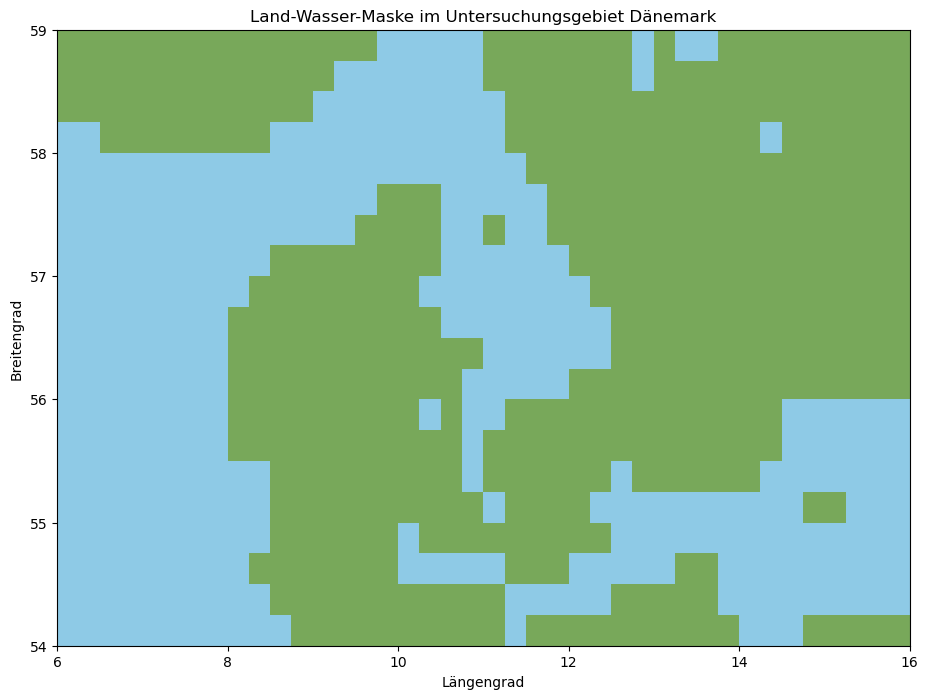

In [8]:
# Diagramm Land-Wasser-Maske erstellen

farben = ListedColormap(["#8ecae6", "#78a85a"])

fig, ax = plt.subplots(figsize=(11, 8))

landmaske.plot(
    ax=ax,
    cmap=farben,
    add_colorbar=False
)

ax.set_title("Land-Wasser-Maske im Untersuchungsgebiet Dänemark")
ax.set_xlabel("Längengrad")
ax.set_ylabel("Breitengrad")

plt.show()

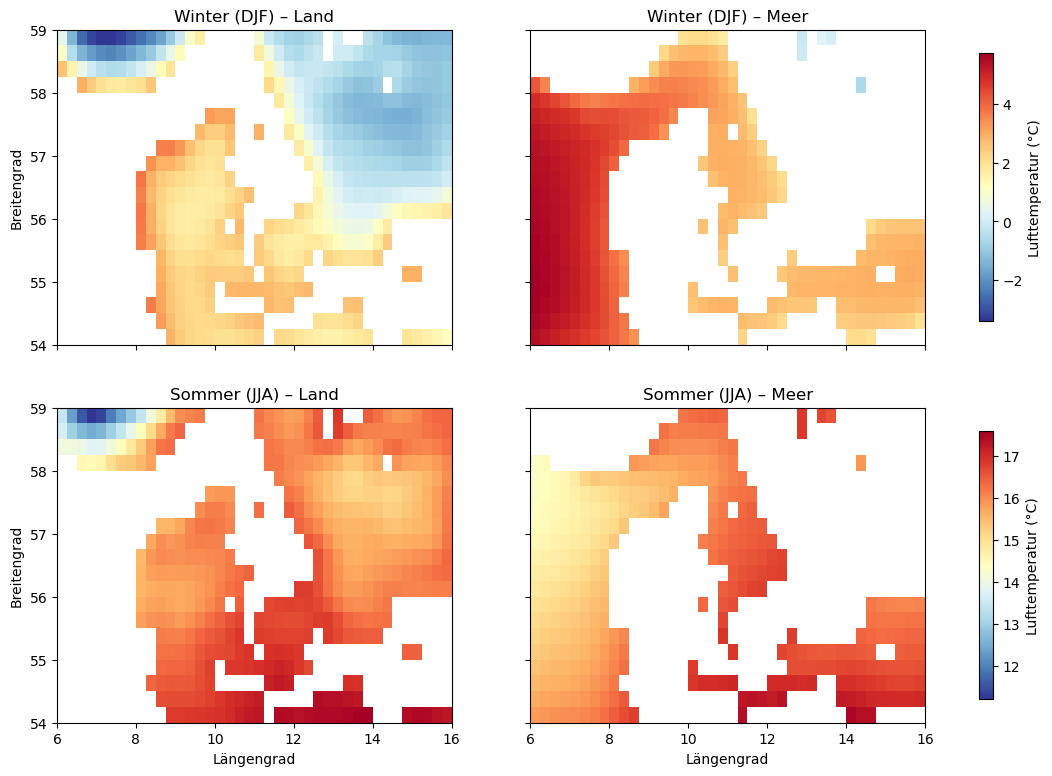

In [10]:
# Klimatologisches Saisonmittel 1991-2020
temp = ds["air_temperature_2m"].sel(time=slice("1991", "2020"), **region)
saison = temp.groupby("time.season").mean("time").compute()

winter = saison.sel(season="DJF")
sommer = saison.sel(season="JJA")

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)

for zeile, (name, feld) in enumerate([("Winter (DJF)", winter), ("Sommer (JJA)", sommer)]):
    # gemeinsame Farbskala pro Jahreszeit für Land UND Meer
    vmin, vmax = float(feld.min()), float(feld.max())

    for spalte, (titel, maske) in enumerate([("Land", landmaske),
                                              ("Meer", meermaske)]):
        ax = axes[zeile, spalte]
        m = feld.where(maske).plot(ax=ax, cmap="RdYlBu_r", vmin=vmin, vmax=vmax,
                                   add_colorbar=False)
        ax.set_title(f"{name} – {titel}")
        ax.set_xlabel("Längengrad" if zeile == 1 else "")
        ax.set_ylabel("Breitengrad" if spalte == 0 else "")

    # eine Farbleiste pro Zeile
    fig.colorbar(m, ax=axes[zeile, :], label="Lufttemperatur (°C)", shrink=0.85)

plt.show()


## Analyse 1: Räumliche Verteilung der jährlichen Temperaturamplitude

Ziel dieser Analyse ist es, die räumliche Verteilung der jährlichen Temperaturamplitude im Untersuchungsgebiet Dänemark sowie den angrenzenden Bereichen der Nord- und Ostsee darzustellen.

Zunächst wird das geografische Untersuchungsgebiet anhand der geografischen Breiten- und Längengrade eingegrenzt. Anschließend werden die Lufttemperaturdaten in 2 m Höhe für den Zeitraum 2001 bis 2020 ausgewählt.

Im nächsten Schritt werden aus den Temperaturdaten monatliche Mittelwerte berechnet. Durch die anschließende Gruppierung nach Kalendermonaten wird ein mittlerer Jahresgang für den gesamten Untersuchungszeitraum erstellt. Dazu werden beispielsweise alle Januarmittelwerte der Jahre 1991 bis 2020 gemittelt.

Die jährliche Temperaturamplitude wird schließlich als Differenz zwischen dem höchsten und niedrigsten monatlichen Mittelwert berechnet. Die Berechnung erfolgt für jeden Rasterpunkt einzeln.

Die resultierenden Werte werden anschließend als räumliche Karte dargestellt. Dadurch lässt sich untersuchen, wie stark die Lufttemperatur im Jahresverlauf schwankt und wie sich die Temperaturamplitude zwischen den Landflächen und den angrenzenden Meeresgebieten unterscheidet.

### 1. Auswahl des Untersuchungszeitraums

Für die Untersuchung wird der Zeitraum 1991–2020 gewählt. Dieser entspricht der klimatologischen Standardnormalperiode der World Meteorological Organization (WMO). Die WMO empfiehlt die Verwendung von 30-jährigen Referenzzeiträumen, um repräsentative mittlere Klimabedingungen zu bestimmen und die Vergleichbarkeit klimatologischer Auswertungen zu gewährleisten (WMO 2017). Der Zeitraum 1991–2020 wird auch von Copernicus als aktuelle klimatologische Standardreferenzperiode verwendet (Copernicus Climate Change Service o. J.).

Durch die Verwendung eines 30-jährigen Zeitraums werden jährliche Temperaturschwankungen ausgeglichen und repräsentative mittlere Klimabedingungen ermittelt. Dadurch eignet sich der Zeitraum zur Untersuchung der durchschnittlichen saisonalen Temperaturamplitude und ihrer räumlichen Unterschiede zwischen Land- und Meeresflächen.



### 2. Berechnung der jährlichen Temperaturamplitude

In [18]:
# Analyse 1: Berechnung der jährlichen Temperaturamplitude

# Auswahl des geografischen Untersuchungsgebiets:
# Dänemark sowie angrenzende Bereiche der Nord- und Ostsee
region = dict(
    lat=slice(54, 59),  # Geografische Breite: 54° bis 59° N
    lon=slice(6, 16)    # Geografische Länge: 6° bis 16° E
)

# Auswahl der Lufttemperatur in 2 m Höhe
# Betrachtungszeitraum: 1991 bis 2020
# Beschränkung auf das definierte Untersuchungsgebiet
temp = ds["air_temperature_2m"].sel(
    time=slice("1991", "2020"),
    **region
)

# Berechnung der monatlichen Mitteltemperaturen
# Resampling auf Monatsanfänge (1MS)
temp_monat = temp.resample(time="1MS").mean()

# Berechnung des mittleren Jahresgangs:
# Für jeden Kalendermonat wird der Mittelwert
# über alle Jahre des Untersuchungszeitraums gebildet
jahresgang = temp_monat.groupby("time.month").mean("time")

# Berechnung der jährlichen Temperaturamplitude:
# Differenz zwischen dem wärmsten und kältesten
# monatlichen Mittelwert an jedem Rasterpunkt
amplitude = jahresgang.max("month") - jahresgang.min("month")



### 3. Erklärung der Berechnung und Interpretation

**Berechnung der Jahresamplitude**

Die jährliche Temperaturamplitude beschreibt die Differenz zwischen dem wärmsten und dem kältesten monatlichen Mittelwert eines Jahresgangs. Sie wird für jeden Rasterpunkt im Untersuchungsgebiet separat berechnet.

Die Berechnung erfolgt nach folgender Formel:


$$
A = T_{\mathrm{max}} - T_{\mathrm{min}}
$$

Dabei gilt:

- $A$: Jährliche Temperaturamplitude in °C
- $T_{\mathrm{max}}$: Höchster monatlicher Mittelwert
- $T_{\mathrm{min}}$: Niedrigster monatlicher Mittelwert


Da die Berechnung auf den gemittelten Monatswerten der Jahre 2001 bis 2020 basiert, beschreibt die Amplitude den durchschnittlichen saisonalen Temperaturunterschied und nicht die absoluten Temperaturrekorde einzelner Tage.

**Interpretation der Ergebnisse**

Die räumliche Verteilung der Temperaturamplitude ermöglicht einen Vergleich zwischen Land- und Meeresflächen.

- **Hohe Temperaturamplitude:** Große Unterschiede zwischen Sommer- und Wintertemperaturen. Diese sind typischerweise im Landesinneren zu erwarten.
- **Niedrige Temperaturamplitude:** Geringere saisonale Temperaturschwankungen. Diese treten typischerweise über dem Meer auf, da Wasser Wärme langsamer aufnimmt und abgibt als Land.
- **Übergangsbereiche an der Küste:** Hier können die Werte zwischen den maritimen und kontinentalen Bedingungen liegen.

**Erwartung:** Die Temperaturamplitude sollte vom Meer über die Küstenregionen in Richtung Landesinneres zunehmen. Dies lässt sich durch die höhere Wärmespeicherkapazität des Wassers erklären. Meeresflächen erwärmen und kühlen sich langsamer ab als Landflächen, wodurch die jahreszeitlichen Temperaturschwankungen geringer ausfallen.

Anhand der Karte wird untersucht, ob sich dieses erwartete räumliche Muster im Untersuchungsgebiet Dänemark und den angrenzenden Meeresgebieten erkennen lässt.


### 4. Räumliche Darstellung der jährlichen Temperaturamplitude

Die berechnete jährliche Temperaturamplitude wird mithilfe von Matplotlib und Cartopy als geografische Karte visualisiert.

Dazu wird zunächst eine Karte mit der geografischen Projektion Plate Carrée erstellt und auf das Untersuchungsgebiet Dänemark sowie die angrenzenden Bereiche der Nord- und Ostsee begrenzt.

Die Temperaturamplitude wird anschließend als farbcodierte Rasterkarte dargestellt. Die verwendete Farbskala reicht von Gelb über Orange bis Rot. Höhere Werte der Temperaturamplitude werden durch intensivere Rottöne dargestellt, während niedrigere Werte gelblich erscheinen.

Zur geografischen Orientierung werden zusätzlich Küstenlinien, Ländergrenzen sowie ein Gitternetz mit Längen- und Breitengraden eingeblendet.

Die Karte ermöglicht einen räumlichen Vergleich der saisonalen Temperaturschwankungen zwischen Land- und Meeresflächen und dient als Grundlage für die anschließende Interpretation der Ergebnisse.



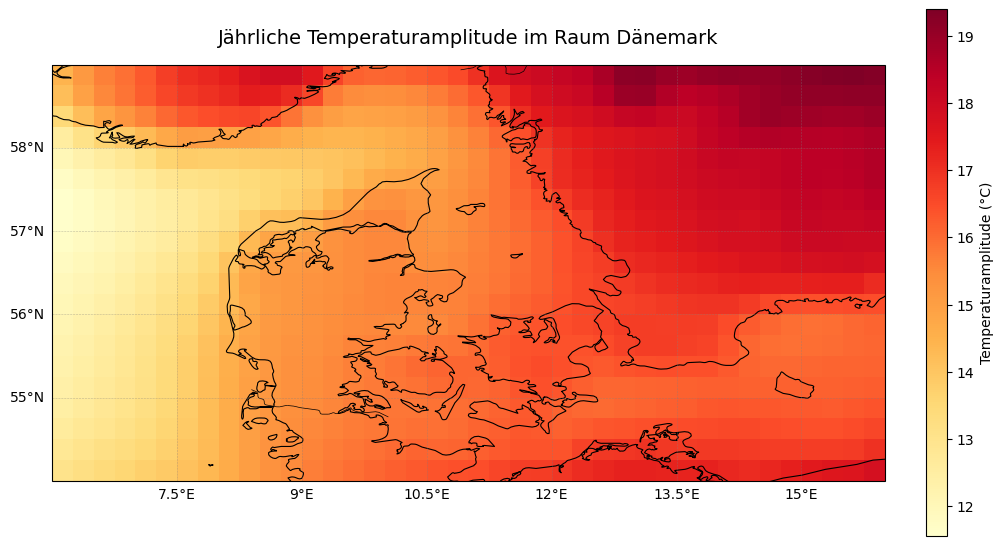

In [21]:

# Erstellung einer Abbildung mit geografischer Kartenprojektion
# figsize: Festlegung der Abbildungsgröße (Breite, Höhe in Zoll)
# PlateCarree: Geografische Projektion mit Längen- und Breitengraden
fig, ax = plt.subplots(
    figsize=(11, 12),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

# Festlegung des geografischen Untersuchungsgebiets
# Grenzen: Längengrad 6°–16° E und Breitengrad 54°–59° N
ax.set_extent([6, 16, 54, 59], crs=ccrs.PlateCarree())

# Darstellung der berechneten Temperaturamplitude als räumliche Farbkarte
# transform: Koordinatensystem der zugrunde liegenden Daten
# cmap: Farbskala von Gelb über Orange bis Rot
# cbar_kwargs: Beschriftung und Größe der Farbskala
amplitude.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="YlOrRd",
    cbar_kwargs={
    "label": "Temperaturamplitude (°C)",
    "shrink": 0.45,
    "aspect": 25,
    "pad": 0.04
    }
)

# Ergänzung geografischer Orientierungselemente
# Küstenlinien zur Abgrenzung von Land- und Meeresflächen
ax.coastlines(resolution="10m", linewidth=0.8)

# Darstellung der Ländergrenzen
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

# Einfügen eines geografischen Gitternetzes
# Anzeige der Längen- und Breitengrade
gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.4,
    color="gray",
    alpha=0.5,
    linestyle="--"
)

# Ausblenden der Beschriftungen am oberen und rechten Kartenrand
gl.top_labels = False
gl.right_labels = False

# Festlegung des Kartentitels und der Schriftgröße
ax.set_title(
    "Jährliche Temperaturamplitude im Raum Dänemark",
    fontsize=14,
    pad=15
)

# Automatische Anpassung der Abstände und Ränder
plt.tight_layout()

#Speichern der Graphik
#fig.savefig("abb_transekt.png", dpi=300, bbox_inches="tight")

# Anzeigen der fertigen Karte
plt.show()

 

### 6. Statistische Auswertung der Temperaturamplitude

Zur Ergänzung der räumlichen Kartenvisualisierung werden die statistischen Kennwerte der jährlichen Temperaturamplitude für das gesamte Untersuchungsgebiet berechnet.

Dabei werden drei Kennwerte bestimmt:

- **Minimum:** Kleinster berechneter Wert der Temperaturamplitude im Untersuchungsgebiet.
- **Maximum:** Größter berechneter Wert der Temperaturamplitude im Untersuchungsgebiet.
- **Mittelwert:** Durchschnittliche Temperaturamplitude über alle Rasterpunkte des Untersuchungsgebiets.

Die Kennwerte geben einen Überblick über die Spannweite und das durchschnittliche Niveau der saisonalen Temperaturschwankungen.

Sie dienen als Grundlage für die quantitative Einordnung der räumlichen Verteilung und ergänzen die visuelle Interpretation der Temperaturkarte.


In [22]:
# Berechnung der statistischen Kennwerte der Temperaturamplitude

# Ermittlung der kleinsten Temperaturamplitude im Untersuchungsgebiet
print("Kleinste Amplitude:", float(amplitude.min().values))

# Ermittlung der größten Temperaturamplitude im Untersuchungsgebiet
print("Größte Amplitude:", float(amplitude.max().values))

# Berechnung der durchschnittlichen Temperaturamplitude
print("Mittlere Amplitude:", float(amplitude.mean().values))


Kleinste Amplitude: 11.558279037475586
Größte Amplitude: 19.388551712036133
Mittlere Amplitude: 15.827381134033203


#### Interpretation der statistischen Kennwerte

Die berechneten Temperaturamplituden liegen im Untersuchungsgebiet zwischen 11,56 °C und 19,39 °C. Die mittlere jährliche Temperaturamplitude beträgt 15,83 °C.

Die Differenz zwischen dem höchsten und niedrigsten Wert beträgt rund 7,83 °C. Dies zeigt, dass die Stärke der saisonalen Temperaturschwankungen innerhalb des Untersuchungsgebiets räumlich variiert.

Die mittlere Amplitude von 15,83 °C verdeutlicht, dass die Lufttemperaturen im Untersuchungsgebiet im Jahresverlauf deutlichen saisonalen Schwankungen unterliegen. Die niedrigeren Amplituden lassen sich insbesondere im Zusammenhang mit dem ausgleichenden Einfluss der angrenzenden Meeresflächen erwarten. Über dem Meer erwärmt sich die Umgebungsluft im Sommer tendenziell weniger stark und kühlt im Winter weniger stark ab als über dem Land.

Die höheren Amplituden sind dagegen mit stärker ausgeprägten jahreszeitlichen Temperaturunterschieden vereinbar, wie sie typischerweise über Landflächen auftreten.

Die statistischen Kennwerte bestätigen somit eine räumliche Variabilität der Temperaturamplitude. Für eine genauere Beurteilung des Land-Meer-Unterschieds müssen die Werte zusätzlich getrennt nach Land- und Meeresflächen betrachtet werden.

## Analyse 2: Quantitativer Vergleich ausgewählter Standorte

In [27]:
# Definition der Untersuchungsstandorte mit ihren geografischen Koordinaten
# Format der Koordinaten: (Breitengrad, Längengrad)
# Alle Standorte liegen auf dem 56. Breitengrad, um den Einfluss
# unterschiedlicher geografischer Breiten möglichst gering zu halten.

standorte = {
    "Nordsee (westlicher Bereich)": (56.125, 0.000, "Wasser"),     # Offene Meeresfläche westlich von Dänemark
    "Nordsee (mittlerer Bereich)":  (56.125,  4.125, "Wasser"),    # Offene Meeresfläche westlich von Dänemark
    "Nordsee (östlicher Bereich)":  (56.125,  6.125, "Wasser"),    # Offene Meeresfläche westlich von Dänemark
    "Westküste Jütland":            (56.125,  8.125, "Küste"),     # Küstenbereich als Übergang zwischen Land und Meer
    "Jütland":                      (56.125,  9.375, "Land"),      # Standort im Landesinneren Dänemarks
    "Südschweden":                  (56.125, 13.875, "Land"),      # Standort im Landesinneren Schwedens
    "Hanöbukten":                   (56.125, 14.450, "Küste"),     # Küstenbereich als Übergang zwischen Land und Meer
    "Ostsee (westlicher Bereich)":  (56.125, 17.625, "Wasser"),    # Offene Meeresfläche östlich von Schweden
    "Ostsee (mittlerer Bereich)":   (56.125, 18.625, "Wasser"),    # Offene Meeresfläche östlich von Schweden
    "Ostsee (östlicher Bereich)":   (56.125, 19.625, "Wasser"),    # Offene Meeresfläche östlich von Schweden
    "Baltikum Küste":               (56.125, 21.125, "Küste"),     # Küstenbereich als Übergang zwischen Land und Meer
    "Baltikum ":                    (56.125, 23.125, "Land"),      # Standort im Landesinneren
    "Westrussland":                 (56.125, 29.125, "Land"),      # Standort im Landesinneren 
    "Zentralrussland":              (56.125, 35.125, "Land"),      # Standort im Landesinneren 
}


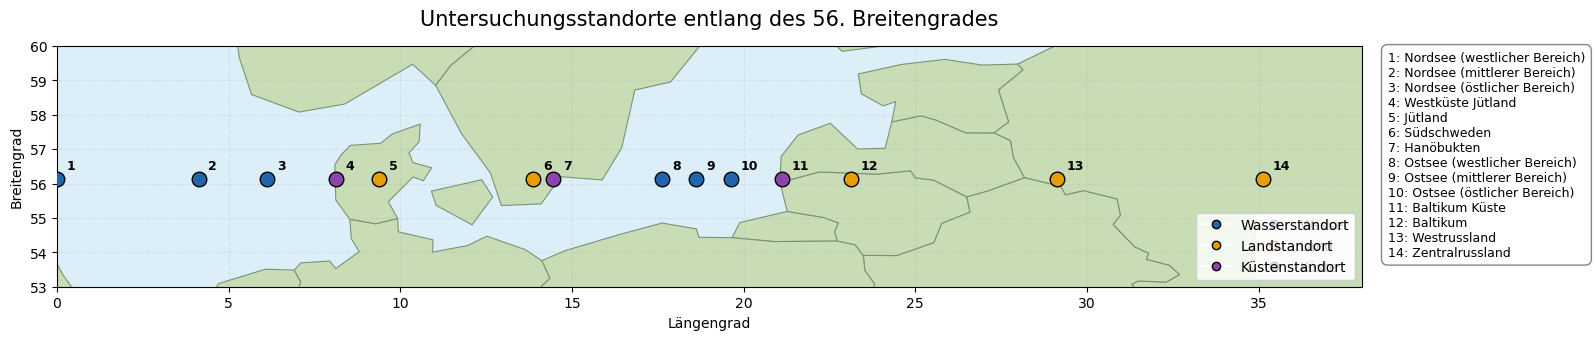

In [32]:
# DataFrame mit geografischen Koordinaten und Gebietstypen erstellen
df = pd.DataFrame([
    {
        "Gebiet": name,
        "Breite": coords[0],
        "Länge": coords[1],
        "Typ": coords[2]
    }
    for name, coords in standorte.items()
])

# GeoDataFrame erstellen
gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["Länge"], df["Breite"]),
    crs="EPSG:4326"
)

# Ländergrenzen laden
welt = gpd.read_file(
    "https://naturalearth.s3.amazonaws.com/110m_cultural/"
    "ne_110m_admin_0_countries.zip"
)

# Farbzuordnung der Gebietstypen
farben = {
    "Wasser": "#2166AC",
    "Land": "#E69F00",
    "Küste": "#8E44AD"
}

# Kartendarstellung
fig, ax = plt.subplots(figsize=(16, 8))

# Hintergrundfarbe = Meer
ax.set_facecolor("#DCEEF7")

# Landflächen zeichnen
welt.plot(
    ax=ax,
    color="#C8DDB5",
    edgecolor="#789477",
    linewidth=0.8
)

# Standorte nach ihrem tatsächlichen Gebietstyp einfärben und nummerieren 
for i, row in gdf.iterrows():

    farbe = farben[row["Typ"]]

    ax.scatter(
        row["Länge"],
        row["Breite"],
        color=farbe,
        edgecolor="black",
        s=110,
        zorder=3
    )

    # Nur Nummer am Standort anzeigen
    ax.annotate(
        str(i + 1),
        (row["Länge"], row["Breite"]),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold"
    )
   

# Kartenausschnitt auf alle Standorte erweitern
ax.set_xlim(0, 38)
ax.set_ylim(53, 60)

# Titel und Achsenbeschriftungen
ax.set_title(
    "Untersuchungsstandorte entlang des 56. Breitengrades",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Längengrad")
ax.set_ylabel("Breitengrad")

ax.grid(alpha=0.25, linestyle="--")


# Legende für die Gebietstypen
legende_typ = [
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor=farben["Wasser"],
           markeredgecolor="black", label="Wasser"),

    Line2D([0], [0], marker="o", color="w",
           markerfacecolor=farben["Land"],
           markeredgecolor="black", label="Land"),

    Line2D([0], [0], marker="o", color="w",
           markerfacecolor=farben["Küste"],
           markeredgecolor="black", label="Küste")
]

leg1 = ax.legend(
    handles=legende_typ,
    loc="lower right"
)

ax.add_artist(leg1)
# Legende für die Standortnummern außerhalb der Karte
standort_legende = "\n".join(
    [f"{i+1}: {name}" for i, name in enumerate(gdf["Gebiet"])]
)

ax.text(
    1.02, 0.98,
    standort_legende,
    transform=ax.transAxes,
    fontsize=9,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        alpha=0.95,
        edgecolor="gray"
    )
)

# Platz rechts für die Legende schaffen
plt.subplots_adjust(right=0.78)


ax.legend(handles=legende, loc="lower right")

plt.tight_layout()

#Speichern der Graphik
#fig.savefig("abb_transekt.png", dpi=300, bbox_inches="tight")

plt.show()

### 1. Jahresamplitude an allen 14 Standorten

In [66]:
# Tageshöchst- und Tagestiefsttemperaturen für alle Standorte auslesen
temperaturen = []

for name, (lat, lon, typ) in standorte.items():

    # Tageshöchsttemperatur
    tmax = ds["max_air_temperature_2m"].sel(
        lat=lat,
        lon=lon,
        method="nearest"
    )

    # Tagestiefsttemperatur
    tmin = ds["min_air_temperature_2m"].sel(
        lat=lat,
        lon=lon,
        method="nearest"
    )

    # DataFrame erstellen
    df = pd.DataFrame({
        "time": tmax.time.values,
        "Tmax": tmax.values,
        "Tmin": tmin.values
    })

    df["Standort"] = name
    df["Gebietstyp"] = typ

    temperaturen.append(df)

# Alle Standorte zusammenführen
df_temp = pd.concat(temperaturen, ignore_index=True)

# Datum formatieren
df_temp["time"] = pd.to_datetime(df_temp["time"])

# Untersuchungszeitraum 1991–2020
df_temp = df_temp[
    (df_temp["time"].dt.year >= 1991) &
    (df_temp["time"].dt.year <= 2020)
]

print(df_temp.head())

          time       Tmax      Tmin                      Standort Gebietstyp
552 1991-01-05  10.694450  3.195450  Nordsee (westlicher Bereich)     Wasser
553 1991-01-13   7.914230  2.863762  Nordsee (westlicher Bereich)     Wasser
554 1991-01-21   9.344452  4.938644  Nordsee (westlicher Bereich)     Wasser
555 1991-01-29   6.850182  3.233276  Nordsee (westlicher Bereich)     Wasser
556 1991-02-06   4.401367  1.454674  Nordsee (westlicher Bereich)     Wasser


In [36]:
# Jahresamplituden berechnen
# Jahr extrahieren
df_temp["Jahr"] = df_temp["time"].dt.year

# Jährliches Maximum und Minimum berechnen
df_amplitude = (
    df_temp.groupby(["Standort", "Gebietstyp", "Jahr"])
    .agg(
        Tmax_Jahr=("Tmax", "max"),
        Tmin_Jahr=("Tmin", "min")
    )
    .reset_index()
)

# Jahresamplitude berechnen
df_amplitude["Amplitude"] = (
    df_amplitude["Tmax_Jahr"] -
    df_amplitude["Tmin_Jahr"]
)

print(df_amplitude)

            Standort Gebietstyp  Jahr  Tmax_Jahr  Tmin_Jahr  Amplitude
0          Baltikum        Land  1991  28.278763 -16.666443  44.945206
1          Baltikum        Land  1992  32.531555 -12.167633  44.699188
2          Baltikum        Land  1993  26.422112 -16.591537  43.013649
3          Baltikum        Land  1994  32.937614 -27.275539  60.213154
4          Baltikum        Land  1995  28.933891 -20.164478  49.098370
..               ...        ...   ...        ...        ...        ...
415  Zentralrussland       Land  2016  31.206459 -25.185719  56.392178
416  Zentralrussland       Land  2017  29.874825 -34.283989  64.158813
417  Zentralrussland       Land  2018  29.454727 -25.869072  55.323799
418  Zentralrussland       Land  2019  29.847588 -20.727245  50.574833
419  Zentralrussland       Land  2020  30.417198 -17.239639  47.656837

[420 rows x 6 columns]


In [37]:
# Mittlere Jahresamplitude berechnen
df_mittel = (
    df_amplitude.groupby(["Standort", "Gebietstyp"])["Amplitude"]
    .mean()
    .reset_index(name="Mittlere_Amplitude")
)

print(df_mittel)

                        Standort Gebietstyp  Mittlere_Amplitude
0                      Baltikum        Land           51.343987
1                 Baltikum Küste      Küste           46.595078
2                     Hanöbukten      Küste           40.276234
3                        Jütland       Land           39.304134
4    Nordsee (mittlerer Bereich)     Wasser           18.738281
5   Nordsee (westlicher Bereich)     Wasser           16.471113
6    Nordsee (östlicher Bereich)     Wasser           20.939919
7     Ostsee (mittlerer Bereich)     Wasser           26.691582
8    Ostsee (westlicher Bereich)     Wasser           25.984486
9     Ostsee (östlicher Bereich)     Wasser           28.527061
10                   Südschweden       Land           43.994724
11             Westküste Jütland      Küste           27.664423
12                  Westrussland       Land           55.033337
13               Zentralrussland       Land           57.914391


In [38]:
print("Anzahl Standorte:", df_amplitude["Standort"].nunique())
print("Anzahl Jahre:", df_amplitude["Jahr"].nunique())
print("Anzahl Jahresamplituden:", len(df_amplitude))

print("\nFehlende Werte:")
print(df_amplitude.isna().sum())

Anzahl Standorte: 14
Anzahl Jahre: 30
Anzahl Jahresamplituden: 420

Fehlende Werte:
Standort      0
Gebietstyp    0
Jahr          0
Tmax_Jahr     0
Tmin_Jahr     0
Amplitude     0
dtype: int64


Mittlere Jahresamplitude je Gebietstyp berechnen

In [39]:
# Mittelwert der Jahresamplituden je Standort
df_mittel = (
    df_amplitude.groupby(["Standort", "Gebietstyp"])["Amplitude"]
    .mean()
    .reset_index(name="Mittlere_Amplitude")
)

# Mittelwert je Gebietstyp
df_gebietstyp = (
    df_mittel.groupby("Gebietstyp")["Mittlere_Amplitude"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

df_gebietstyp = df_gebietstyp.rename(columns={
    "mean": "Durchschnittliche_Amplitude",
    "std": "Standardabweichung",
    "count": "Anzahl_Standorte"
})

print(df_gebietstyp.round(2))

  Gebietstyp  Durchschnittliche_Amplitude  Standardabweichung  \
0      Küste                    38.180000                9.64   
1       Land                    49.520000                7.73   
2     Wasser                    22.889999                4.86   

   Anzahl_Standorte  
0                 3  
1                 5  
2                 6  


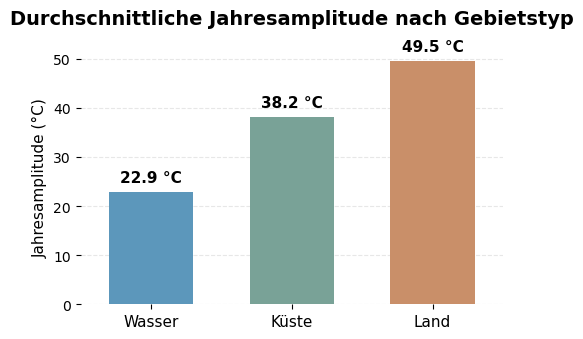

In [63]:
plt.figure(figsize=(5, 3.5))

farben = ["#4C9BCB", "#72A99A", "#D98B59"]

ax = sns.barplot(
    data=df_gebietstyp,
    x="Gebietstyp",
    y="Durchschnittliche_Amplitude",
    order=["Wasser", "Küste", "Land"],
    hue="Gebietstyp",
    hue_order=["Wasser", "Küste", "Land"],
    palette=farben,
    legend=False,
    width=0.6
)

# Werte über den Balken anzeigen
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f °C",
        padding=5,
        fontsize=11,
        fontweight="bold"
    )

# Titel und Achsen
plt.title(
    "Durchschnittliche Jahresamplitude nach Gebietstyp",
    fontsize=14,
    fontweight="bold",
    pad=18
)

plt.xlabel("")
plt.ylabel("Jahresamplitude (°C)", fontsize=11)

# Dezentes Raster
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.gca().set_axisbelow(True)

# Rahmen entfernen
sns.despine(left=True, bottom=True)

# Achsenbeschriftung
plt.xticks(fontsize=11)
plt.yticks(fontsize=10)

plt.tight_layout()

#Speichern der Graphik
#fig.savefig("abb_transekt.png", dpi=300, bbox_inches="tight")

plt.show()

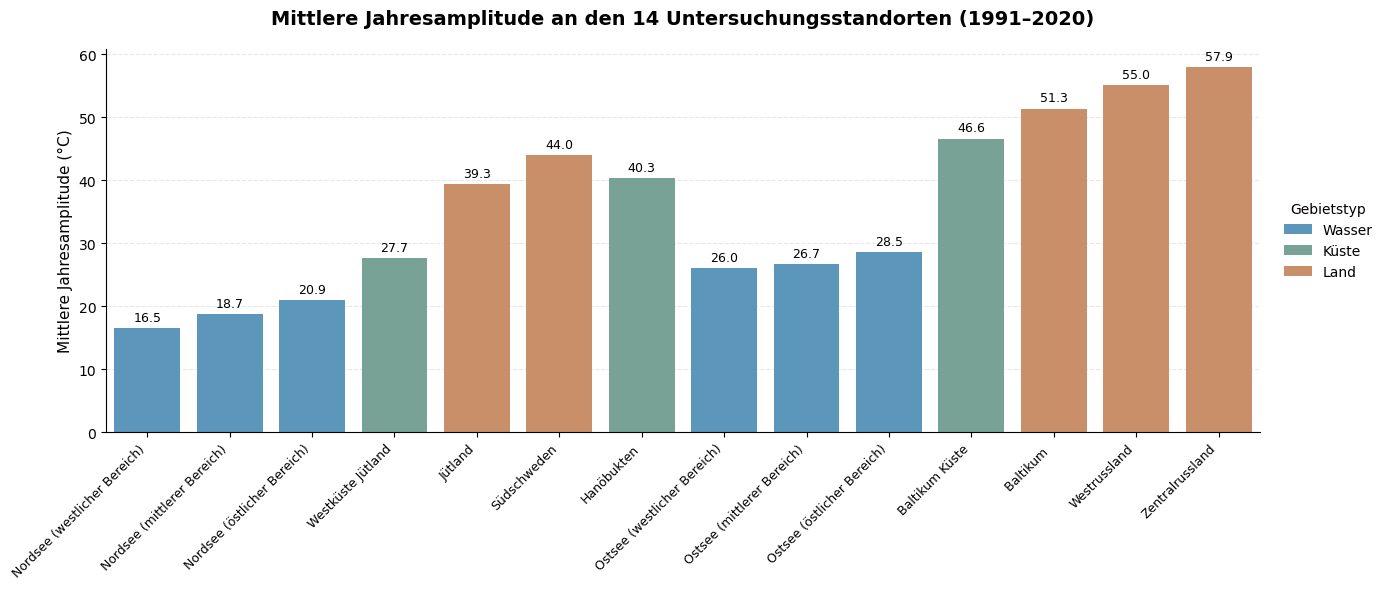

In [60]:
plt.figure(figsize=(14, 6))

farben = {
    "Wasser": "#4C9BCB",
    "Küste": "#72A99A",
    "Land": "#D98B59"
}

# Standorte nach Längengrad sortieren
standort_reihenfolge = sorted(
    standorte.keys(),
    key=lambda name: standorte[name][1]
)

ax = sns.barplot(
    data=df_mittel,
    x="Standort",
    y="Mittlere_Amplitude",
    hue="Gebietstyp",
    order=standort_reihenfolge,
    hue_order=["Wasser", "Küste", "Land"],
    palette=farben,
    dodge=False
)

# Werte über den Balken anzeigen
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f",
        padding=3,
        fontsize=9
    )

# Titel
plt.title(
    "Mittlere Jahresamplitude an den 14 Untersuchungsstandorten (1991–2020)",
    fontsize=14,
    fontweight="bold",
    pad=18
)

plt.xlabel("")
plt.ylabel("Mittlere Jahresamplitude (°C)", fontsize=11)

# Standortnamen lesbar darstellen
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(fontsize=10)

# Dezentes Raster
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.gca().set_axisbelow(True)

# Legende
#plt.xticks(rotation=45, ha="right")

plt.legend(
    title="Gebietstyp",
    frameon=False,
    loc="center left",
    bbox_to_anchor=(1.01, 0.5)
)

sns.despine()
plt.tight_layout()

#Speichern der Graphik
#fig.savefig("abb_transekt.png", dpi=300, bbox_inches="tight")

plt.show()


In [42]:
# Koordinaten aus dem Dictionary übernehmen
df_koordinaten = pd.DataFrame([
    {
        "Standort": name,
        "Breitengrad": lat,
        "Laengengrad": lon,
        "Gebietstyp": typ
    }
    for name, (lat, lon, typ) in standorte.items()
])

# Koordinaten mit mittleren Amplituden verbinden
df_west_ost = df_mittel.merge(
    df_koordinaten,
    on=["Standort", "Gebietstyp"]
)

# Nach geografischer Länge sortieren
df_west_ost = df_west_ost.sort_values("Laengengrad")

print(df_west_ost.round(2))

                        Standort Gebietstyp  Mittlere_Amplitude  Breitengrad  \
5   Nordsee (westlicher Bereich)     Wasser           16.469999        56.12   
4    Nordsee (mittlerer Bereich)     Wasser           18.740000        56.12   
6    Nordsee (östlicher Bereich)     Wasser           20.940001        56.12   
11             Westküste Jütland      Küste           27.660000        56.12   
3                        Jütland       Land           39.299999        56.12   
10                   Südschweden       Land           43.990002        56.12   
2                     Hanöbukten      Küste           40.279999        56.12   
8    Ostsee (westlicher Bereich)     Wasser           25.980000        56.12   
7     Ostsee (mittlerer Bereich)     Wasser           26.690001        56.12   
9     Ostsee (östlicher Bereich)     Wasser           28.530001        56.12   
1                 Baltikum Küste      Küste           46.599998        56.12   
0                      Baltikum        L

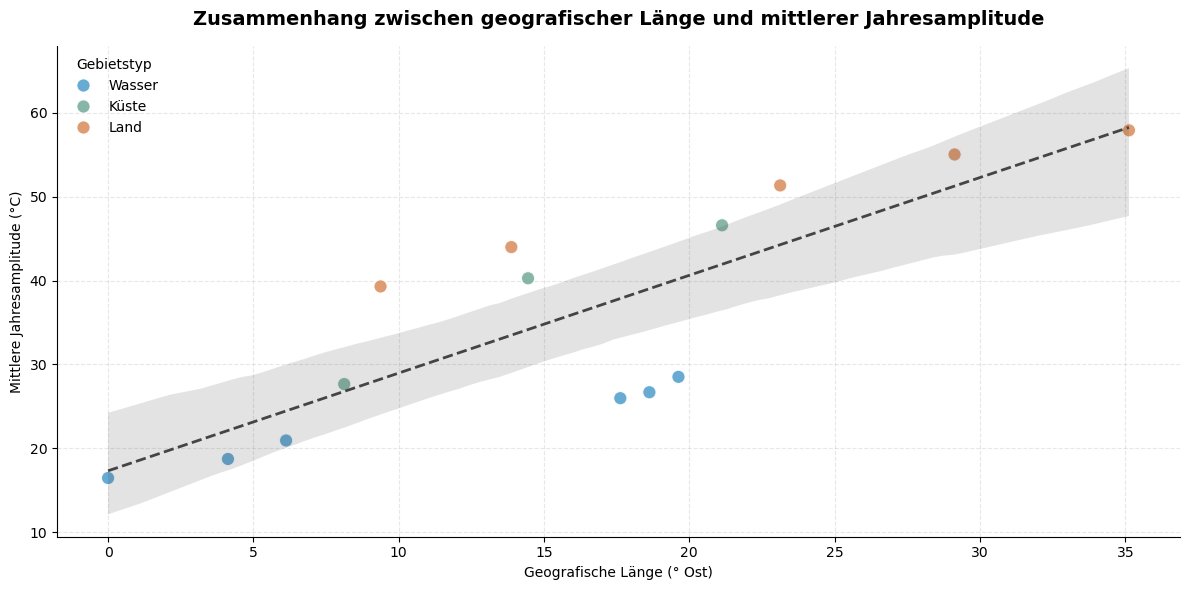

In [62]:
plt.figure(figsize=(12, 6))

farben = {
    "Wasser": "#4C9BCB",
    "Küste": "#72A99A",
    "Land": "#D98B59"
}

ax = sns.scatterplot(
    data=df_west_ost,
    x="Laengengrad",
    y="Mittlere_Amplitude",
    hue="Gebietstyp",
    hue_order=["Wasser", "Küste", "Land"],
    palette=farben,
    s=90,
    alpha=0.85
)

# Lineare Trendlinie über alle Standorte
sns.regplot(
    data=df_west_ost,
    x="Laengengrad",
    y="Mittlere_Amplitude",
    scatter=False,
    color="#444444",
    line_kws={"linewidth": 2, "linestyle": "--"},
    ci=95,
    ax=ax
)

plt.title(
    "Zusammenhang zwischen geografischer Länge und mittlerer Jahresamplitude",
    fontsize=14,
    fontweight="bold",
    pad=15
)
plt.xlabel("Geografische Länge (° Ost)")
plt.ylabel("Mittlere Jahresamplitude (°C)")

plt.legend(title="Gebietstyp", frameon=False)
plt.grid(True, linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

sns.despine()
plt.tight_layout()

#Speichern der Graphik
#fig.savefig("abb_transekt.png", dpi=300, bbox_inches="tight")

plt.show()

In [45]:
from scipy.stats import linregress

# Lineare Regression
regression = linregress(
    df_west_ost["Laengengrad"],
    df_west_ost["Mittlere_Amplitude"]
)

print("Steigung:", round(regression.slope, 3))
print("Korrelationskoeffizient:", round(regression.rvalue, 3))
print("Bestimmtheitsmaß R²:", round(regression.rvalue**2, 3))
print("p-Wert:", round(regression.pvalue, 4))

Steigung: 1.165
Korrelationskoeffizient: 0.822
Bestimmtheitsmaß R²: 0.676
p-Wert: 0.0003


##### Zusammenhang zwischen geografischer Länge und Jahresamplitude

Die lineare Regressionsanalyse zeigt einen deutlichen positiven Zusammenhang zwischen der geografischen Länge und der mittleren Jahresamplitude der 14 Untersuchungsstandorte im Zeitraum 1991–2020. Der Korrelationskoeffizient beträgt r = 0,822 und weist auf eine starke positive Korrelation hin. Das Bestimmtheitsmaß von R² = 0,676 bedeutet, dass 67,6 % der räumlichen Variation der mittleren Jahresamplituden durch das lineare Regressionsmodell beschrieben werden.

Die Steigung der Regressionsgeraden beträgt 1,165 °C pro Längengrad. Damit nehmen die Jahresamplituden innerhalb des untersuchten Transekts tendenziell von Westen nach Osten zu. Der Zusammenhang ist mit einem p-Wert von 0,0003 statistisch signifikant.

Diese Entwicklung ist mit dem Übergang von maritimen zu kontinentaleren Klimabedingungen vereinbar. Während die Nähe zum Meer temperaturausgleichend wirkt, können im Landesinneren stärkere saisonale Temperaturschwankungen auftreten. Die Ergebnisse unterstützen somit die Annahme, dass der kontinentale Klimaeinfluss entlang des untersuchten West-Ost-Transekts zunimmt.

### 2. Entwicklung der Temperatur im Jahresverlauf

In [68]:
# Liste für die Temperaturdaten aller Standorte erstellen
temperaturen = []

# Alle sechs Standorte durchlaufen
for name, (lat, lon, typ) in standorte.items():

    # Mittlere Lufttemperatur in 2 m Höhe auslesen
    # nearest wählt den nächstgelegenen Gitterpunkt
    temp = ds["air_temperature_2m"].sel(
        lat=lat,
        lon=lon,
        method="nearest"
    )

    # Temperaturdaten in einen DataFrame übertragen
    df = pd.DataFrame({
        "time": temp.time.values,
        "Tmittel": temp.values
    })

    # Standortinformationen ergänzen
    df["Standort"] = name
    df["Gebietstyp"] = typ

    # DataFrame zur Gesamtliste hinzufügen
    temperaturen.append(df)


# Daten aller Standorte zusammenführen
df_temp = pd.concat(temperaturen, ignore_index=True)

# Zeitangaben in Datumsformat umwandeln
df_temp["time"] = pd.to_datetime(df_temp["time"])

# Nur den Untersuchungszeitraum 1991 bis 2020 berücksichtigen
df_temp = df_temp[
    (df_temp["time"].dt.year >= 1991) &
    (df_temp["time"].dt.year <= 2020)
]

# Jahr als zusätzliche Spalte extrahieren
df_temp["Jahr"] = df_temp["time"].dt.year

# Erste Zeilen anzeigen
print(df_temp.head())

          time   Tmittel                      Standort Gebietstyp  Jahr
552 1991-01-05  6.311236  Nordsee (westlicher Bereich)     Wasser  1991
553 1991-01-13  5.794302  Nordsee (westlicher Bereich)     Wasser  1991
554 1991-01-21  6.923248  Nordsee (westlicher Bereich)     Wasser  1991
555 1991-01-29  4.731757  Nordsee (westlicher Bereich)     Wasser  1991
556 1991-02-06  2.934377  Nordsee (westlicher Bereich)     Wasser  1991


In [69]:
# Jahresmitteltemperatur für jeden Standort berechnen
jahresmittel = (
    df_temp
    .groupby(["Standort", "Gebietstyp", "Jahr"])["Tmittel"]
    .mean()
    .reset_index()
)

# Spaltennamen anpassen
jahresmittel.rename(
    columns={"Tmittel": "Jahresmitteltemperatur"},
    inplace=True
)

# Ergebnisse anzeigen
print(jahresmittel.head(10))

    Standort Gebietstyp  Jahr  Jahresmitteltemperatur
0  Baltikum        Land  1991                6.941597
1  Baltikum        Land  1992                7.388455
2  Baltikum        Land  1993                6.136595
3  Baltikum        Land  1994                6.610933
4  Baltikum        Land  1995                6.684415
5  Baltikum        Land  1996                5.109953
6  Baltikum        Land  1997                6.697227
7  Baltikum        Land  1998                6.423740
8  Baltikum        Land  1999                7.467825
9  Baltikum        Land  2000                7.881012


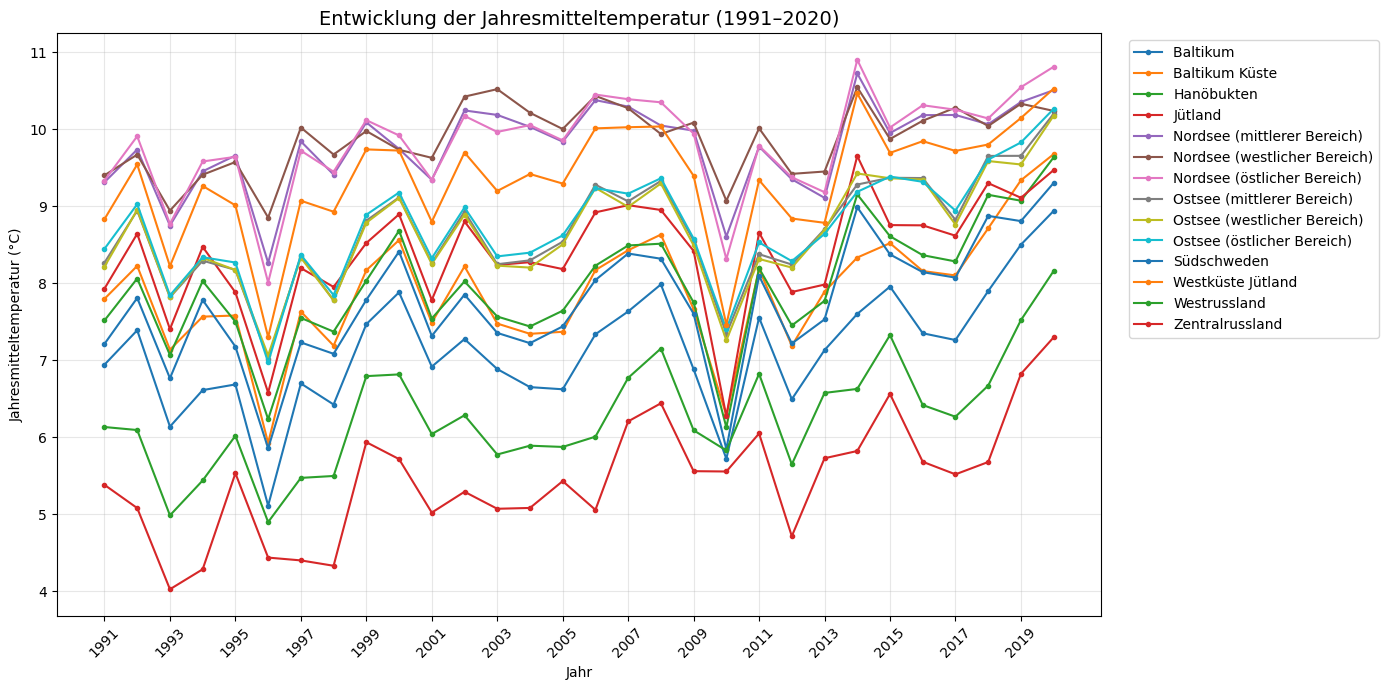

In [70]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

# Für jeden Standort eine eigene Temperaturkurve zeichnen
for name in jahresmittel["Standort"].unique():

    daten = jahresmittel[
        jahresmittel["Standort"] == name
    ]

    plt.plot(
        daten["Jahr"],
        daten["Jahresmitteltemperatur"],
        marker="o",
        markersize=3,
        label=name
    )

# Diagramm beschriften
plt.title(
    "Entwicklung der Jahresmitteltemperatur (1991–2020)",
    fontsize=14
)

plt.xlabel("Jahr")
plt.ylabel("Jahresmitteltemperatur (°C)")

plt.xticks(range(1991, 2021, 2), rotation=45)
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

In [81]:
from scipy.stats import linregress

# Liste für die Ergebnisse erstellen
trend_ergebnisse = []

# Jeden Standort einzeln untersuchen
for name in jahresmittel["Standort"].unique():

    daten = jahresmittel[
        jahresmittel["Standort"] == name
    ]

    # Lineare Regression berechnen
    ergebnis = linregress(
        daten["Jahr"],
        daten["Jahresmitteltemperatur"]
    )

    # Ergebnisse speichern
    trend_ergebnisse.append({
        "Standort": name,
        "Gebietstyp": daten["Gebietstyp"].iloc[0],
        "Steigung °C/Jahr": ergebnis.slope,
        "Erwärmung °C/Dekade": ergebnis.slope * 10,
        "R²": ergebnis.rvalue ** 2,
        "p-Wert": ergebnis.pvalue
    })

# Ergebnisse als Tabelle ausgeben
trend_tabelle = pd.DataFrame(trend_ergebnisse)

#print(trend_tabelle.round(4))

In [80]:
#Tabelle erstellen

# Spaltenüberschriften anpassen
trend_tabelle = trend_tabelle.rename(columns={
    "Standort": "Untersuchungsstandort",
    "Steigung °C/Jahr": "Trend (°C/Jahr)",
    "Erwärmung °C/Dekade": "Erwärmung (°C/Dekade)",
    "R²": "Bestimmtheitsmaß (R²)",
    "p-Wert": "p-Wert"
})

# Standorte nach Längengrad sortieren (West nach Ost)
standort_reihenfolge = sorted(
    standorte.keys(),
    key=lambda name: standorte[name][1]
)

# Tabelle geografisch sortieren
trend_tabelle["Untersuchungsstandort"] = pd.Categorical(
    trend_tabelle["Untersuchungsstandort"],
    categories=standort_reihenfolge,
    ordered=True
)

trend_tabelle = trend_tabelle.sort_values(
    by="Untersuchungsstandort"
).reset_index(drop=True)

# Tabelle anzeigen
display(trend_tabelle)

,Untersuchungsstandort,Gebietstyp,Trend (°C/Jahr),Erwärmung (°C/Dekade),Bestimmtheitsmaß (R²),p-Wert
0,Nordsee (westlicher Bereich),Wasser,0.024920,0.249199,0.228884,0.007489
1,Nordsee (mittlerer Bereich),Wasser,0.030588,0.305879,0.220949,0.008766
2,Nordsee (östlicher Bereich),Wasser,0.035530,0.355301,0.226256,0.007891
3,Westküste Jütland,Küste,0.039297,0.392969,0.211793,0.010499
4,Jütland,Land,0.038331,0.383305,0.202440,0.012606
5,Südschweden,Land,0.052256,0.522563,0.323929,0.001030
6,Hanöbukten,Küste,0.049871,0.498713,0.311675,0.001346
7,Ostsee (westlicher Bereich),Wasser,0.046274,0.462737,0.336560,0.000778
8,Ostsee (mittlerer Bereich),Wasser,0.047774,0.477739,0.355567,0.000506
9,Ostsee (östlicher Bereich),Wasser,0.046283,0.462830,0.337147,0.000768


#### Entwicklung der Jahresmitteltemperaturen im Zeitraum 1991–2020

Die lineare Trendanalyse der Jahresmitteltemperaturen zeigt an allen 14 untersuchten Standorten eine positive Temperaturentwicklung im Zeitraum von 1991 bis 2020. Die berechneten Erwärmungsraten liegen zwischen 0,25 und 0,59 °C pro Jahrzehnt. Dabei treten deutliche regionale Unterschiede auf.

Die geringste Erwärmungsrate wurde mit 0,25 °C pro Jahrzehnt im westlichen Bereich der Nordsee festgestellt. Auch die übrigen Nordseestandorte weisen mit 0,31 bis 0,36 °C pro Jahrzehnt vergleichsweise geringe Werte auf. Demgegenüber zeigen die Ostseestandorte höhere Erwärmungsraten zwischen 0,46 und 0,48 °C pro Jahrzehnt.

An den Landstandorten fallen die Trends überwiegend stärker aus. Besonders hohe Werte wurden in Zentralrussland mit 0,59 °C pro Jahrzehnt, in Westrussland mit 0,54 °C pro Jahrzehnt und in Südschweden mit 0,52 °C pro Jahrzehnt ermittelt. Die Küstenstandorte weisen Erwärmungsraten zwischen 0,39 und 0,50 °C pro Jahrzehnt auf.

Die Bestimmtheitsmaße liegen zwischen 0,20 und 0,45. Damit erklärt das lineare Modell je nach Standort etwa 20 bis 45 % der beobachteten jährlichen Temperaturschwankungen. Alle berechneten Trends sind auf dem 5-%-Signifikanzniveau statistisch signifikant (p < 0,05).

Insgesamt deuten die Ergebnisse auf eine stärkere Erwärmung an den untersuchten Landstandorten und in der Ostsee im Vergleich zu den Nordseestandorten hin. Die Unterschiede zwischen Nord- und Ostsee zeigen jedoch, dass die Temperaturentwicklung nicht ausschließlich von der Lage über Land oder Wasser abhängt. Regionale klimatische und geografische Einflüsse müssen bei der Interpretation ebenfalls berücksichtigt werden.

### 3. Vergleich zwischen Sommer- und Wintertemperaturen

### Auswahl und Begründung der Untersuchungsjahre

Für die detaillierte Untersuchung der saisonalen Temperaturverläufe wurden die Jahre 2010, 2014, 2018 und 2020 aus dem Gesamtzeitraum 1991 bis 2020 ausgewählt. Die Auswahl erfolgte gezielt, um unterschiedliche klimatische Bedingungen und insbesondere die Unterschiede zwischen vergleichsweise kalten und außergewöhnlich warmen Jahren zu berücksichtigen.

Das Jahr 2010 wurde als vergleichsweise kaltes Jahr ausgewählt. In Dänemark betrug die Jahresmitteltemperatur lediglich 7,0 °C und lag damit deutlich unter dem Mittelwert der Referenzperiode 1991–2020 von 8,7 °C (DMI, 2021). Im Gegensatz dazu stellt das Jahr 2014 ein besonders warmes Vergleichsjahr dar. Mit einer Jahresmitteltemperatur von 10,0 °C war es das wärmste Jahr in Dänemark seit Beginn der landesweiten Temperaturmessungen im Jahr 1874 (DMI, 2015).

Das Jahr 2018 wurde aufgrund des außergewöhnlich warmen Sommers berücksichtigt. Nach Angaben des Copernicus Climate Change Service gehörte der Sommer 2018 zu den wärmsten europäischen Sommern seit Beginn der Aufzeichnungen. Insbesondere in Nordeuropa wurden überdurchschnittlich hohe Temperaturen beobachtet (Copernicus Climate Change Service, o. J.). Das Jahr 2020 ergänzt die Auswahl als weiteres außergewöhnlich warmes Jahr. In Dänemark wurde eine Jahresmitteltemperatur von 9,8 °C gemessen, womit es das zweitwärmste Jahr seit 1874 war (DMI, 2021).

Die ausgewählten Jahre ermöglichen somit einen gezielten Vergleich unterschiedlicher klimatischer Bedingungen. Im Mittelpunkt steht die Frage, ob sich die jahreszeitlichen Temperaturverläufe und die Unterschiede zwischen Meeres-, Küsten- und Binnenlandstandorten in kühleren und wärmeren Jahren unterschiedlich ausgeprägt zeigen. Die vier Jahre dienen dabei als ausgewählte Fallbeispiele innerhalb des 30-jährigen Untersuchungszeitraums.

###### 2014

In [1]:
# Temperaturdaten aus dem Jahr 2014 auswählen
df_jahr14 = df_temp[
    df_temp["time"].dt.year == 2014
].copy()

# Gewünschte Standorte
auswahl = [
    "Nordsee (mittlerer Bereich)",
    "Westküste Jütland",
    "Jütland",
    "Ostsee (mittlerer Bereich)",
    "Baltikum Küste",
    "Baltikum"
]

# Monat extrahieren
df_jahr14["Monat"] = df_jahr14["time"].dt.month

# Monatsmitteltemperatur berechnen
monatsmittel_2014 = (
    df_jahr14
    .groupby(["Standort", "Gebietstyp", "Monat"])["Tmittel"]
    .mean()
    .reset_index()
)

# Nur gewünschte Standorte übernehmen
monatsmittel_2014 = monatsmittel_2014[
    monatsmittel_2014["Standort"].str.strip().isin(auswahl)
].copy()

# Spaltennamen anpassen
monatsmittel_2014.rename(
    columns={"Tmittel": "Temperatur"},
    inplace=True
)


NameError: name 'df_temp' is not defined

In [2]:
import matplotlib.pyplot as plt

# Farben nach Gebietstyp festlegen
farben = {
    "Wasser": "royalblue",
    "Küste": "darkcyan",
    "Land": "darkorange"
}

plt.figure(figsize=(12, 6))

# Temperaturverläufe aller ausgewählten Standorte
for name, gruppe in df_auswahl.groupby("Standort"):

    # Gebietstyp des Standorts bestimmen
    gebietstyp = gruppe["Gebietstyp"].iloc[0]

    plt.plot(
        gruppe["Monat"],
        gruppe["Temperatur"],
        marker="o",
        linewidth=2,
        color=farben[gebietstyp],
        label=name
    )

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun",
     "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
)

plt.xlabel("Monat")
plt.ylabel("Mittlere Lufttemperatur (°C)")
plt.title("Monatlicher Temperaturverlauf nach Gebietstyp – 2014")

plt.legend(title="Standort")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'df_auswahl' is not defined

<Figure size 1200x600 with 0 Axes>

###### 2018

In [3]:
# Temperaturdaten aus dem Jahr 2018 auswählen
df_jahr18 = df_temp[
    df_temp["time"].dt.year == 2018
].copy()

# Gewünschte Standorte
auswahl = [
    "Nordsee (mittlerer Bereich)",
    "Westküste Jütland",
    "Jütland",
    "Ostsee (mittlerer Bereich)",
    "Baltikum Küste",
    "Baltikum"
]

# Monat extrahieren
df_jahr18["Monat"] = df_jahr18["time"].dt.month

# Monatsmitteltemperatur berechnen
monatsmittel_2018 = (
    df_jahr18
    .groupby(["Standort", "Gebietstyp", "Monat"])["Tmittel"]
    .mean()
    .reset_index()
)

# Nur gewünschte Standorte übernehmen
monatsmittel_2018 = monatsmittel_2018[
    monatsmittel_2018["Standort"].str.strip().isin(auswahl)
].copy()

# Spaltennamen anpassen
monatsmittel_2018.rename(
    columns={"Tmittel": "Temperatur"},
    inplace=True
)

#print(monatsmittel_2018["Standort"].unique())

NameError: name 'df_temp' is not defined

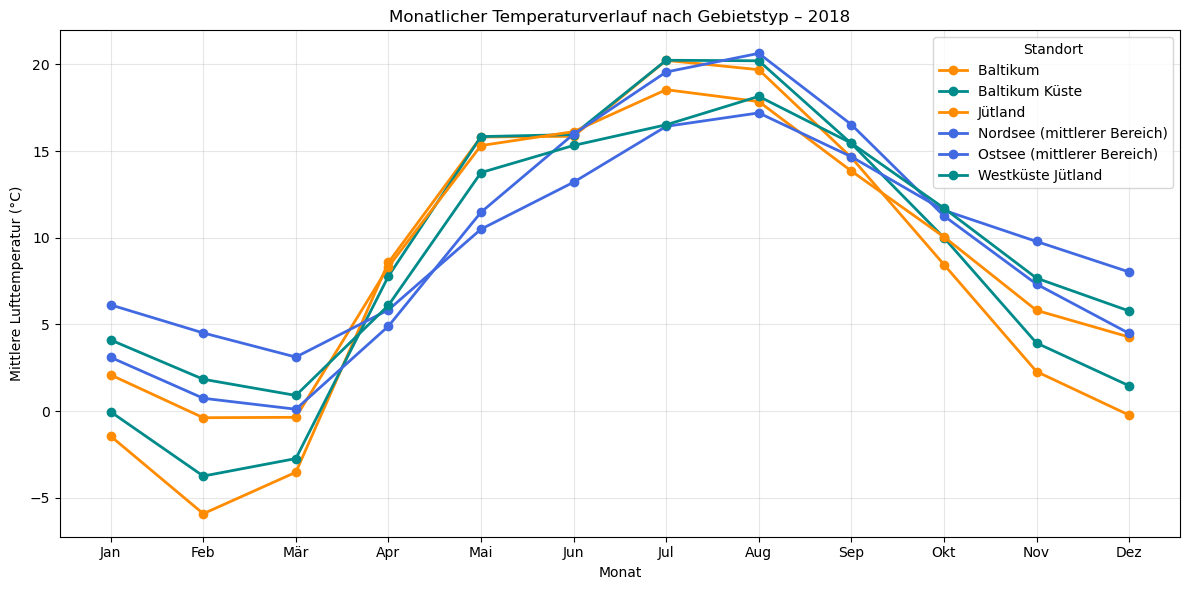

In [117]:
import matplotlib.pyplot as plt

# Farben nach Gebietstyp festlegen
farben = {
    "Wasser": "royalblue",
    "Küste": "darkcyan",
    "Land": "darkorange"
}

plt.figure(figsize=(12, 6))

# Temperaturverläufe aller ausgewählten Standorte
for name, gruppe in df_auswahl.groupby("Standort"):

    # Gebietstyp des Standorts bestimmen
    gebietstyp = gruppe["Gebietstyp"].iloc[0]

    plt.plot(
        gruppe["Monat"],
        gruppe["Temperatur"],
        marker="o",
        linewidth=2,
        color=farben[gebietstyp],
        label=name
    )

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun",
     "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
)

plt.xlabel("Monat")
plt.ylabel("Mittlere Lufttemperatur (°C)")
plt.title("Monatlicher Temperaturverlauf nach Gebietstyp – 2018")

plt.legend(title="Standort")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Amplitude für jedes Jahr berechnen

### Auswertung der jährlichen Temperaturamplituden

Die berechneten Temperaturamplituden zeigen deutliche Unterschiede zwischen den Untersuchungsstandorten. Besonders auffällig ist die Nordsee, die in allen vier untersuchten Jahren die geringsten Temperaturamplituden aufweist. Diese liegen zwischen 8,97 °C und 12,01 °C. Dies deutet auf vergleichsweise geringe jahreszeitliche Schwankungen der Lufttemperatur hin und entspricht der Erwartung eines temperaturausgleichenden maritimen Einflusses.

Die übrigen Meeresstandorte Öresund und Hanöbukten zeigen hingegen deutlich höhere Amplituden. Teilweise liegen diese sogar über den Werten der Inlandstandorte. Auch Südschweden weist vergleichsweise hohe Temperaturschwankungen auf. Damit lässt sich kein allgemeingültiger Zusammenhang zwischen der Lage am Meer und einer geringeren Temperaturamplitude feststellen.

Über alle vier Untersuchungsjahre betrachtet, beträgt die durchschnittliche Temperaturamplitude an der Nordsee 10,16 °C, während sie im dänischen Inland 17,90 °C erreicht. Die Ergebnisse sprechen somit für einen ausgeprägten Temperatureinfluss am Nordsee-Standort. Die Unterschiede zwischen den übrigen Standorten verdeutlichen jedoch, dass weitere geografische und klimatische Einflussfaktoren berücksichtigt werden müssen.

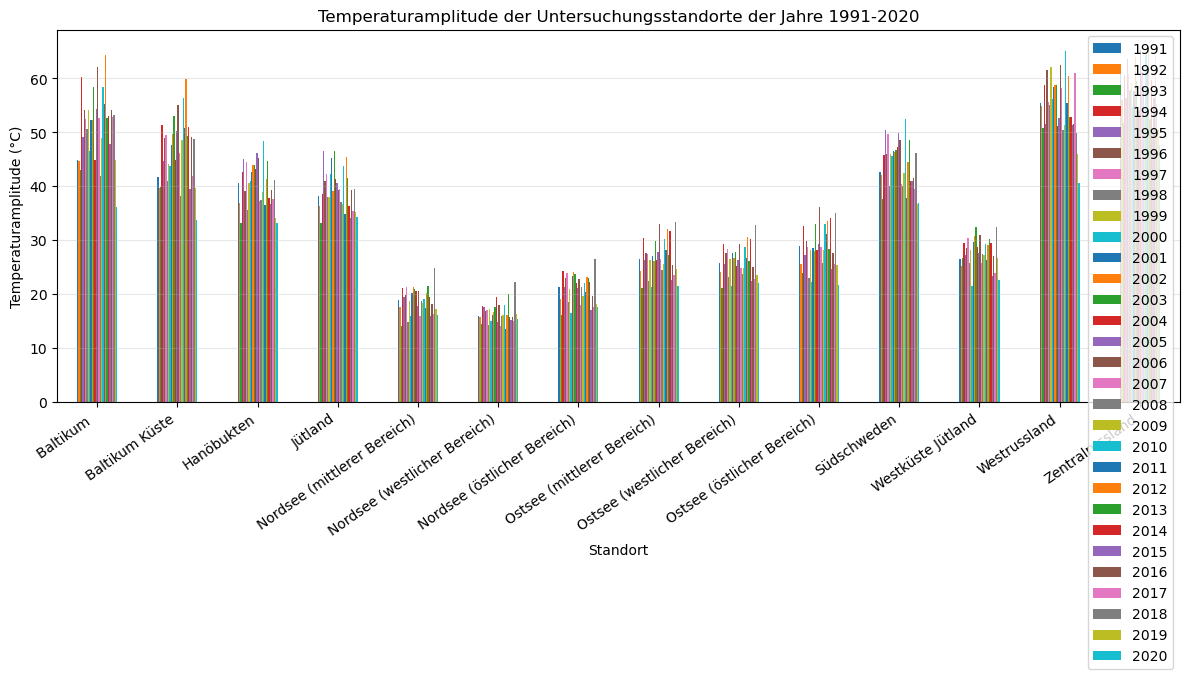

In [105]:


df_pivot = df_amplitude.pivot(
    index="Standort",
    columns="Jahr",
    values="Amplitude"
)

df_pivot.plot(kind="bar", figsize=(12, 6))

plt.title("Temperaturamplitude der Untersuchungsstandorte der Jahre 1991-2020")
plt.xlabel("Standort")
plt.ylabel("Temperaturamplitude (°C)")
plt.xticks(rotation=35, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Heatmap für einzelne Jahre erstellen

In [118]:
def erstelle_heatmap(df, jahr):

    pivot = df.pivot_table(
        index="Standort",
        columns="Monat",
        values="Temperatur",
        aggfunc="mean"
    )

    pivot = pivot.reindex(columns=range(1, 13))

    pivot.columns = [
        "Jan", "Feb", "Mär", "Apr", "Mai", "Jun",
        "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"
    ]

    plt.figure(figsize=(14, 6))

    sns.heatmap(
        pivot,
        annot=True,
        fmt=".1f",
        cmap="RdYlBu_r",
        linewidths=0.5,
        vmin=df["Temperatur"].min(),
        vmax=df["Temperatur"].max(),
        cbar_kws={"label": "Lufttemperatur (°C)"}
    )

    plt.title(f"Monatliche mittlere Lufttemperaturen – {jahr}")
    plt.xlabel("Monat")
    plt.ylabel("Untersuchungsstandort")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

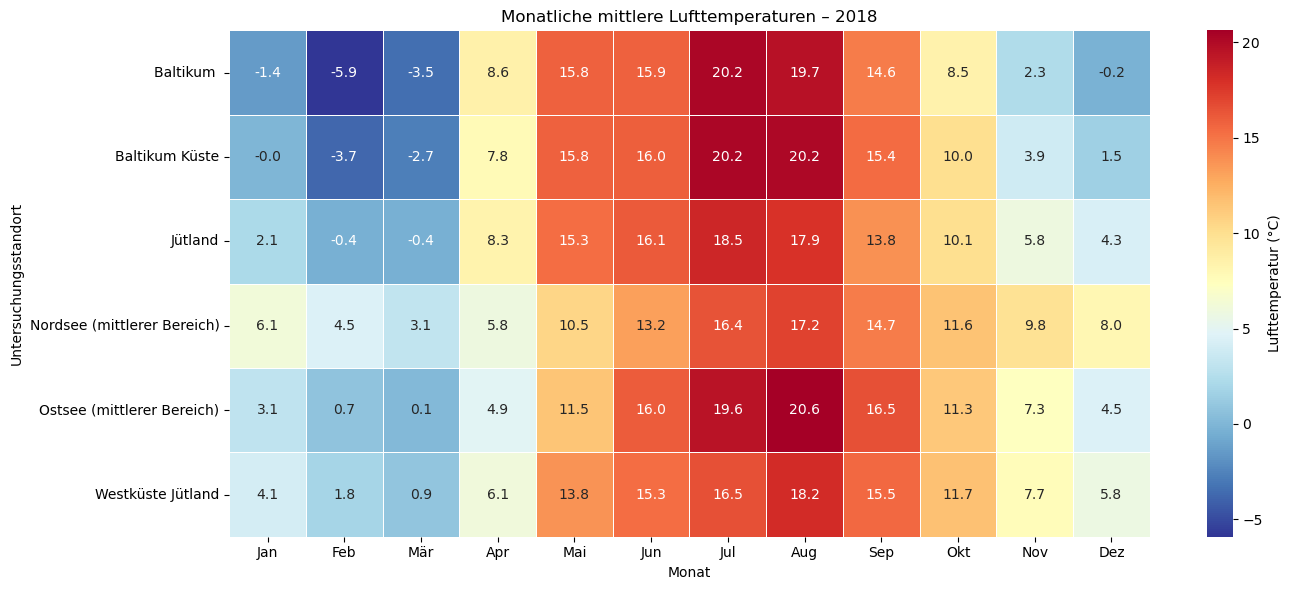

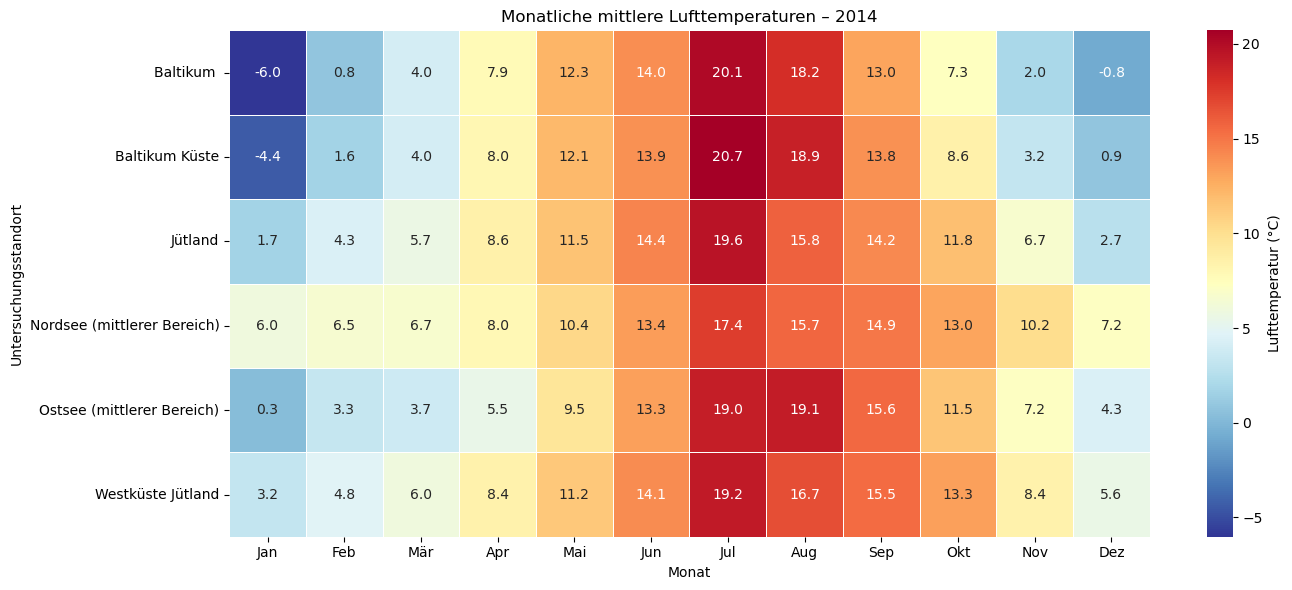

In [126]:
erstelle_heatmap(monatsmittel_2018, 2018)
erstelle_heatmap(monatsmittel_2014, 2014)

#### Jahreszeitlicher Temperaturverlauf

Die Heatmaps zeigen an allen untersuchten Standorten einen ausgeprägten jahreszeitlichen Temperaturverlauf. Die niedrigsten Temperaturen treten überwiegend in den Wintermonaten auf, während die höchsten Temperaturen in den Sommermonaten erreicht werden. Damit wird der typische saisonale Verlauf der Lufttemperatur in der untersuchten Region sichtbar.

#### Unterschiede zwischen Wasser- und Landstandorten

Beim Vergleich der Standorte fällt auf, dass die Nordsee eine vergleichsweise geringe jährliche Temperaturschwankung aufweist. Die Temperaturen unterscheiden sich dort zwischen den Winter- und Sommermonaten weniger stark als an den meisten anderen Standorten. Dies könnte auf den ausgleichenden Einfluss des Meeres zurückzuführen sein.

Bei den weiteren Wasserstandorten, insbesondere Öresund und Hanöbukten, ist dieses Muster allerdings nicht in gleicher Weise ausgeprägt. Ihre Temperaturverläufe zeigen teilweise deutliche saisonale Unterschiede. Auch die Landstandorte weisen vergleichsweise starke Schwankungen auf.

#### Vergleich der Untersuchungsjahre

Durch den Vergleich der Heatmaps für 2010, 2014, 2018 und 2020 lassen sich Unterschiede zwischen den einzelnen Jahren erkennen. Dabei ist insbesondere interessant, ob sich die saisonalen Temperaturmuster an allen Standorten ähnlich verändern oder ob einzelne Standorte abweichende Entwicklungen zeigen.

## Erweiterung: Gebiet vergrößern, Maske prüfen, Küstenentfernung Das Untersuchungsgebiet reicht jetzt entlang 56° N von der Nordsee über Dänemark und Südschweden und die Ostsee bis ins Baltikum und nach Westrussland (Moskau liegt bei ca. 55,75° N / 37,6° O). Damit gibt es erstmals Landflächen, die mehrere hundert Kilometer von der Küste entfernt sind.

In [127]:
# Großes Rechengebiet. Es ist bewusst größer als der Bereich, den wir später auswerten,
# damit der Gebietsrand bei der Distanzberechnung nicht als "Küste" zählt.
region_gross = dict(lat=slice(50, 62), lon=slice(-5, 40))
karten_extent = [-5, 40, 50, 62]          # Kartenausschnitt (lon_min, lon_max, lat_min, lat_max)
klima = slice("1991", "2020")             # Zeitraum der Klimatologie 1991-2020

# Landmaske: Zelle ist Land, wenn GPP in mindestens einem Zeitschritt einen Wert hat.
# Über mehrere Jahre ist das robuster als ein einzelner Tag.
gpp = ds["gross_primary_productivity"].sel(time=klima, **region_gross)
landmaske = gpp.notnull().any("time").compute()
print("Maske:", landmaske.dims, landmaske.shape, "| Landanteil:", round(float(landmaske.mean()), 2))

Maske: ('lat', 'lon') (48, 180) | Landanteil: 0.73


In [128]:


voll = np.ones((3, 3), dtype=bool)        # 8er-Nachbarschaft
land = landmaske.values.astype(bool)

# border_value=1: Der Gebietsrand zählt nicht als Gegenklasse
reines_land   = ndimage.binary_erosion(land,  structure=voll, border_value=1)
reines_wasser = ndimage.binary_erosion(~land, structure=voll, border_value=1)

def als_da(arr):
    return xr.DataArray(arr, coords=landmaske.coords, dims=landmaske.dims)

reines_land_da, reines_wasser_da = als_da(reines_land), als_da(reines_wasser)

# Klassen: 0 Wasser (rein), 1 Küstenwasser, 2 Küstenland, 3 Land (rein)
klasse = np.select(
    [reines_wasser, ~land, ~reines_land, True],
    [0, 1, 2, 3]
)
klasse_da = als_da(klasse)

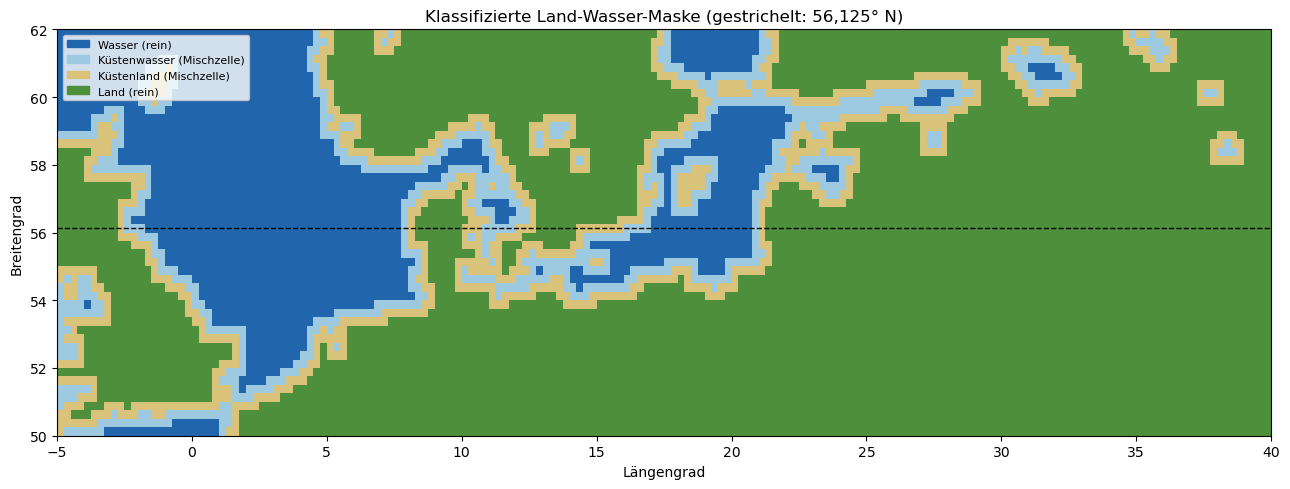

In [129]:


farben = ["#2166AC", "#9ecae1", "#d9c27a", "#4d8f3a"]
namen  = ["Wasser (rein)", "Küstenwasser (Mischzelle)", "Küstenland (Mischzelle)", "Land (rein)"]

fig, ax = plt.subplots(figsize=(13, 5))
ax.pcolormesh(landmaske.lon, landmaske.lat, klasse_da, cmap=ListedColormap(farben),
              vmin=-0.5, vmax=3.5, shading="nearest")
ax.axhline(56.125, color="k", ls="--", lw=1)
ax.set_xlabel("Längengrad"); ax.set_ylabel("Breitengrad")
ax.set_title("Klassifizierte Land-Wasser-Maske (gestrichelt: 56,125° N)")
ax.legend(handles=[Patch(color=f, label=n) for f, n in zip(farben, namen)],
          loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

In [130]:
lat_mid = 56.0
dy = 0.25 * 111.2                                   # km pro Zelle in Nord-Süd-Richtung
dx = 0.25 * 111.2 * np.cos(np.deg2rad(lat_mid))     # km pro Zelle in Ost-West-Richtung (bei 56° N)

# Ozean = große zusammenhängende Wasserflächen (Nordsee, Ostsee), keine Binnenseen
wasser = ~land
lab, n = ndimage.label(wasser, structure=voll)
groessen = ndimage.sum(wasser, lab, index=np.arange(1, n + 1))
ozean = np.isin(lab, np.where(groessen >= 100)[0] + 1)

d_land = ndimage.distance_transform_edt(~ozean, sampling=(dy, dx))  # Nicht-Ozean -> nächster Ozean
d_meer = ndimage.distance_transform_edt(~land,  sampling=(dy, dx))  # Wasser -> nächstes Land

dist = np.where(land, d_land, -d_meer)
dist_da = als_da(dist)
print(f"Maximale Küstenentfernung im Gebiet: {dist.max():.0f} km")

Maximale Küstenentfernung im Gebiet: 1293 km


In [131]:
t_monat = (ds["air_temperature_2m"]
           .sel(time=klima, **region_gross)
           .resample(time="1MS").mean())

jahresgang = t_monat.groupby("time.month").mean("time").compute()
amplitude = (jahresgang.max("month") - jahresgang.min("month")).transpose(*landmaske.dims)
print("Amplitude min/max:", float(amplitude.min()), float(amplitude.max()))

Amplitude min/max: 6.173264026641846 28.128957748413086


In [132]:
# Name: (Breite, Länge, erwarteter Typ)  –  Typ: "Wasser", "Küste" oder "Land"
standorte = {
    "Nordsee 1":            (56.125,  4.125, "Wasser"),
     "Nordsee 2":            (56.125,  6.125, "Wasser"),
    "Westküste Jütland":  (56.125,  8.125, "Küste"),
    "Jütland":            (56.125,  9.375, "Land"),
    "Südschweden":        (56.125, 13.875, "Land"),
     "Ostsee 1":             (56.125, 17.625, "Wasser"),
    "Ostsee 2":             (56.125, 18.625, "Wasser"),
     "Ostsee 3":             (56.125, 19.625, "Wasser"),
    "Baltikum (Küste)":   (56.125, 21.125, "Küste"),
    "Baltikum (inland)":  (56.125, 23.125, "Land"),
    "Westrussland":       (56.125, 29.125, "Land"),
    "Zentralrussland":    (56.125, 35.125, "Land"),
}

zeilen = []
for name, (lat, lon, typ) in standorte.items():
    i = int(np.abs(landmaske.lat.values - lat).argmin())
    j = int(np.abs(landmaske.lon.values - lon).argmin())
    if typ == "Land":
        passt = bool(reines_land[i, j])
    elif typ == "Wasser":
        passt = bool(reines_wasser[i, j])
    else:  # Küste: Landzelle, die an Wasser grenzt
        passt = bool(land[i, j] and not reines_land[i, j])
    zeilen.append({
        "Standort": name,
        "Zelle (lat, lon)": (float(landmaske.lat[i]), float(landmaske.lon[j])),
        "erwartet": typ,
        "Maske": "Land" if land[i, j] else "Wasser",
        "Passt": passt,
        "Küstenentfernung (km)": round(float(dist[i, j])),
        "Amplitude (°C)": round(float(amplitude[i, j]), 1),
    })

df_standorte = pd.DataFrame(zeilen)
df_standorte

,Standort,"Zelle (lat, lon)",erwartet,Maske,Passt,Küstenentfernung (km),Amplitude (°C)
0,Nordsee 1,"(56.125, 4.125)",Wasser,Wasser,True,-249,10.9
1,Nordsee 2,"(56.125, 6.125)",Wasser,Wasser,True,-124,12.0
2,Westküste Jütland,"(56.125, 8.125)",Küste,Land,True,16,14.3
3,Jütland,"(56.125, 9.375)",Land,Land,True,93,15.4
4,Südschweden,"(56.125, 13.875)",Land,Land,True,54,17.0
5,Ostsee 1,"(56.125, 17.625)",Wasser,Wasser,True,-68,16.4
6,Ostsee 2,"(56.125, 18.625)",Wasser,Wasser,True,-85,16.7
7,Ostsee 3,"(56.125, 19.625)",Wasser,Wasser,True,-93,17.1
8,Baltikum (Küste),"(56.125, 21.125)",Küste,Land,True,16,19.4
9,Baltikum (inland),"(56.125, 23.125)",Land,Land,True,140,20.7


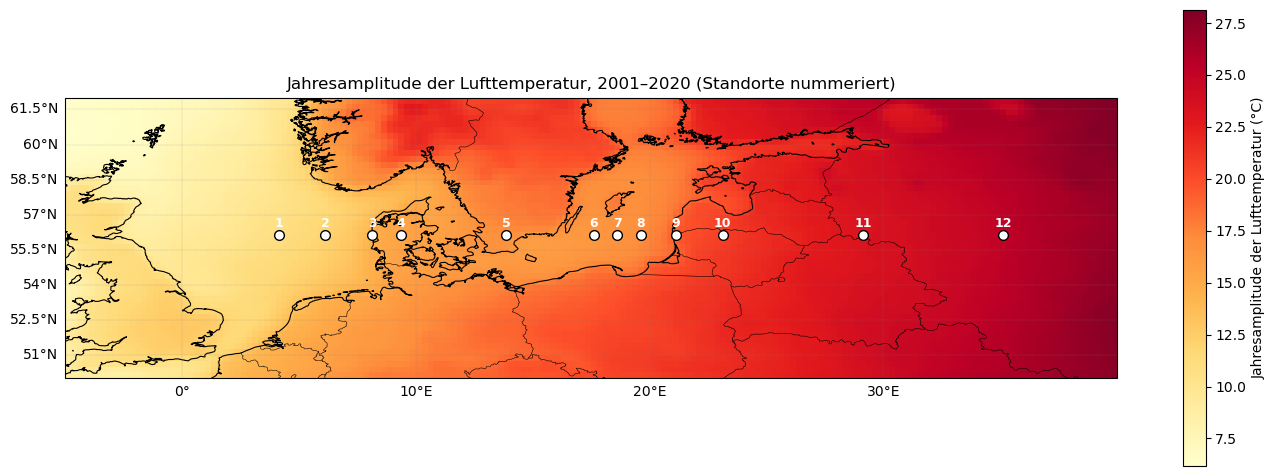

In [133]:


fig, ax = plt.subplots(figsize=(14, 6), subplot_kw={"projection": ccrs.PlateCarree()})
ax.set_extent(karten_extent, crs=ccrs.PlateCarree())

m = amplitude.plot(ax=ax, transform=ccrs.PlateCarree(), cmap="YlOrRd",
                   cbar_kwargs={"label": "Jahresamplitude der Lufttemperatur (°C)", "shrink": 0.8})
ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)

for k, (name, (lat, lon, typ)) in enumerate(standorte.items(), start=1):
    ax.plot(lon, lat, "o", color="white", mec="k", ms=7, transform=ccrs.PlateCarree())
    ax.text(lon, lat + 0.35, str(k), ha="center", fontsize=9, fontweight="bold", color="white",
            transform=ccrs.PlateCarree())

gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.5, linestyle="--")
gl.top_labels = gl.right_labels = False
ax.set_title("Jahresamplitude der Lufttemperatur, 2001–2020 (Standorte nummeriert)")
plt.tight_layout(); plt.show()

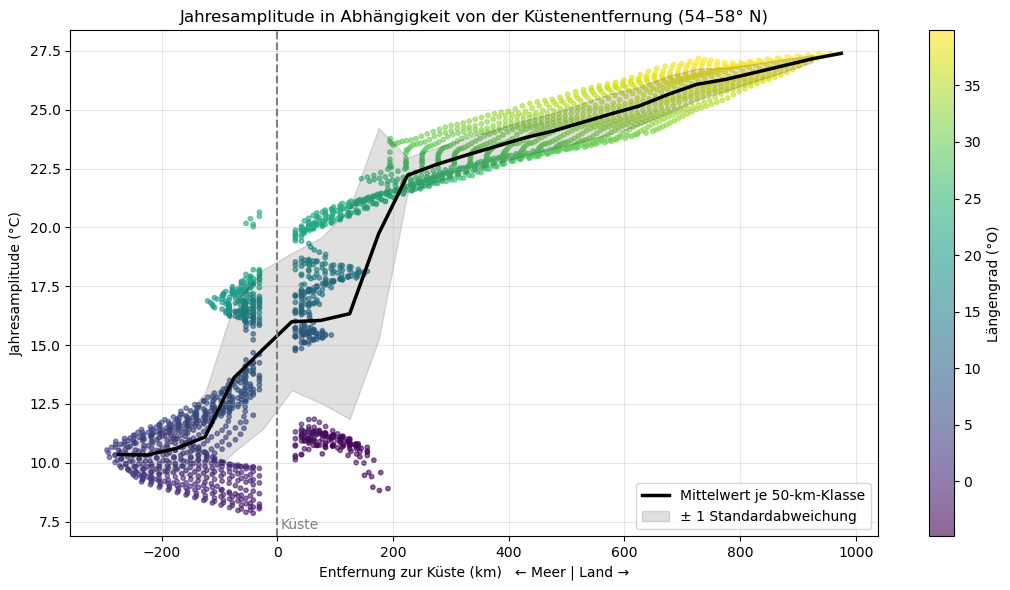

In [134]:
df = xr.Dataset({
    "amp": amplitude,
    "dist": dist_da,
    "rein_land": reines_land_da,
    "rein_wasser": reines_wasser_da,
}).to_dataframe().reset_index()

band = df[(df.lat >= 54) & (df.lat <= 58) & (df.rein_land | df.rein_wasser)].copy()

# Mittelwert und Streuung je 50-km-Klasse
klassen = np.arange(-450, 1251, 50)
band["klasse"] = pd.cut(band["dist"], klassen)
stat = band.groupby("klasse", observed=True)["amp"].agg(["mean", "std", "count"]).reset_index()
stat["mitte"] = stat["klasse"].apply(lambda iv: iv.mid)

fig, ax = plt.subplots(figsize=(11, 6))
sc = ax.scatter(band["dist"], band["amp"], c=band["lon"], cmap="viridis", s=10, alpha=0.6)
plt.colorbar(sc, ax=ax, label="Längengrad (°O)")
ax.plot(stat["mitte"], stat["mean"], "k-", lw=2.5, label="Mittelwert je 50-km-Klasse")
ax.fill_between(stat["mitte"], stat["mean"] - stat["std"], stat["mean"] + stat["std"],
                color="k", alpha=0.12, label="± 1 Standardabweichung")
ax.axvline(0, color="gray", ls="--")
ax.text(5, ax.get_ylim()[0] + 0.3, "Küste", color="gray")
ax.set_xlabel("Entfernung zur Küste (km)   ← Meer | Land →")
ax.set_ylabel("Jahresamplitude (°C)")
ax.set_title("Jahresamplitude in Abhängigkeit von der Küstenentfernung (54–58° N)")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

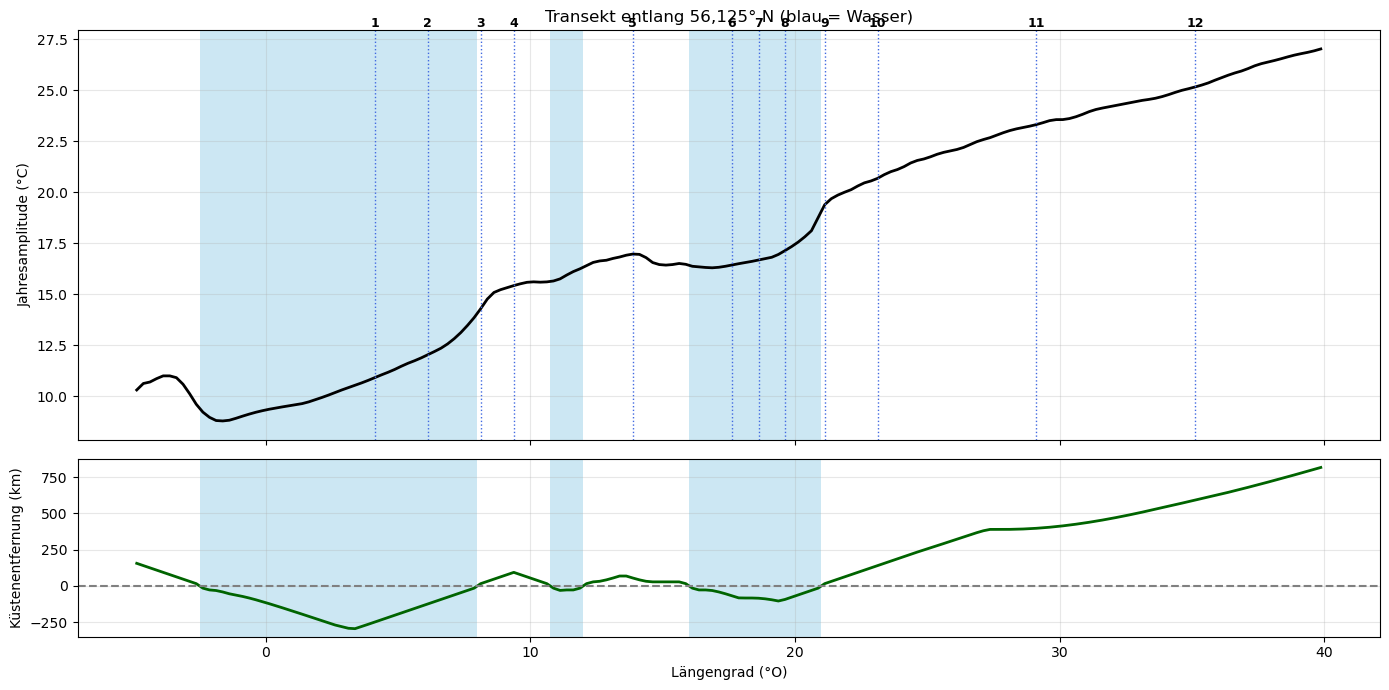

In [135]:
tr = amplitude.sel(lat=56.125, method="nearest")
lm = landmaske.sel(lat=56.125, method="nearest")
dt = dist_da.sel(lat=56.125, method="nearest")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1.3]})

# Wasserflächen blau hinterlegen
for lon, ist_land in zip(tr.lon.values, lm.values):
    if not ist_land:
        for ax in (ax1, ax2):
            ax.axvspan(lon - 0.125, lon + 0.125, color="#8ecae6", alpha=0.45, lw=0)

ax1.plot(tr.lon, tr, "k-", lw=2)
ax1.set_ylabel("Jahresamplitude (°C)")
ax1.set_title("Transekt entlang 56,125° N (blau = Wasser)")
ax1.grid(alpha=0.3)
for k, (name, (lat, lon, typ)) in enumerate(standorte.items(), start=1):
    ax1.axvline(lon, color="royalblue", ls=":", lw=1)
    ax1.text(lon, ax1.get_ylim()[1], str(k), ha="center", va="bottom", fontsize=9, fontweight="bold")

ax2.plot(dt.lon, dt, color="darkgreen", lw=2)
ax2.axhline(0, color="gray", ls="--")
ax2.set_ylabel("Küstenentfernung (km)")
ax2.set_xlabel("Längengrad (°O)")
ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

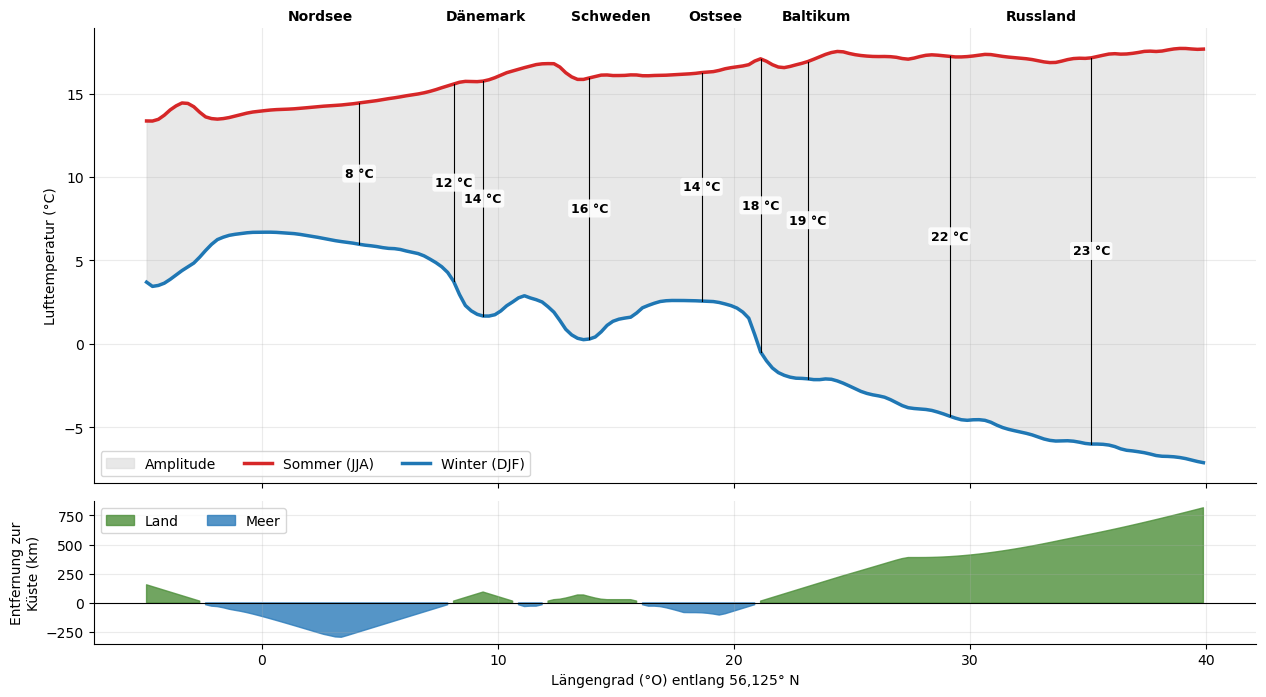

In [136]:
# Saisonmittel 2001–2020 entlang 56,125° N
temp = ds["air_temperature_2m"].sel(time=klima, **region_gross)
saison = temp.groupby("time.season").mean("time").compute()

winter = saison.sel(season="DJF").sel(lat=56.125, method="nearest")
sommer = saison.sel(season="JJA").sel(lat=56.125, method="nearest")
dt     = dist_da.sel(lat=56.125, method="nearest")
lon    = winter.lon.values
amp    = (sommer - winter).values

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True,
                               gridspec_kw={"height_ratios": [3.2, 1], "hspace": 0.06})

# --- oben: Sommer- und Wintermittel, Fläche dazwischen = Amplitude ---
ax1.fill_between(lon, winter, sommer, color="#d9d9d9", alpha=0.6, label="Amplitude")
ax1.plot(lon, sommer, color="#d62728", lw=2.5, label="Sommer (JJA)")
ax1.plot(lon, winter, color="#1f77b4", lw=2.5, label="Winter (DJF)")
ax1.set_ylabel("Lufttemperatur (°C)")
ax1.grid(alpha=0.25)
ax1.legend(loc="lower left", frameon=True, ncol=3)

# Amplitudenwerte an ausgewählten Standorten direkt beschriften
standort_auswahl = {
    "Nordsee 1":            (56.125,  4.125, "Wasser"),
    "Westküste Jütland":  (56.125,  8.125, "Küste"),
    "Jütland":            (56.125,  9.375, "Land"),
    "Südschweden":        (56.125, 13.875, "Land"),
    "Ostsee 2":             (56.125, 18.625, "Wasser"),
    "Baltikum (Küste)":   (56.125, 21.125, "Küste"),
    "Baltikum (inland)":  (56.125, 23.125, "Land"),
    "Westrussland":       (56.125, 29.125, "Land"),
    "Zentralrussland":    (56.125, 35.125, "Land"),
}


for name, (lat, lx, typ) in standort_auswahl.items():
    k = int(np.abs(lon - lx).argmin())
    ax1.annotate(f"{amp[k]:.0f} °C", (lon[k], (winter[k] + sommer[k]) / 2 ),
                 ha="center", va="center", fontsize=9, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
    ax1.plot([lon[k]] * 2, [winter[k], sommer[k]], color="k", lw=0.8)

# Regionsnamen oben im Diagramm
regionen = {"Nordsee": 2.5, "Dänemark": 9.5, "Schweden": 14.8, "Ostsee": 19.2,
            "Baltikum": 23.5, "Russland": 33}
for name, x in regionen.items():
    ax1.text(x, 1.01, name, transform=ax1.get_xaxis_transform(),
             ha="center", va="bottom", fontsize=10, fontweight="bold")

# --- unten: Küstenentfernung als Fläche (blau = Meer, grün = Land) ---
ax2.fill_between(lon, dt, 0, where=dt >= 0, color="#4d8f3a", alpha=0.8, label="Land")
ax2.fill_between(lon, dt, 0, where=dt < 0, color="#2b7bba", alpha=0.8, label="Meer")
ax2.axhline(0, color="k", lw=0.8)
ax2.set_ylabel("Entfernung zur\nKüste (km)")
ax2.set_xlabel("Längengrad (°O) entlang 56,125° N")
ax2.grid(alpha=0.25)
ax2.legend(loc="upper left", ncol=2)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
fig.savefig("abb_transekt.png", dpi=300, bbox_inches="tight")
plt.show()